## 1. Kurulum ve Kütüphaneler

In [ ]:
!pip -q install vit_pytorch einops timm
!pip -q install kaggle

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 186.5/186.5 kB 14.4 MB/s eta 0:00:00


In [ ]:
from __future__ import print_function, division

import numpy as np
import os
import time
import copy
import json
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import defaultdict

use_gpu = torch.cuda.is_available()
device = torch.device('cuda' if use_gpu else 'cpu')
print(f'Cihaz: {device}')
torch.manual_seed(42)
np.random.seed(42)

Cihaz: cuda


## 2. Veri Seti İndirme ve Yükleme

In [ ]:
# Kişisel erişim bilgileri yerel ortamda tutulur; bu not defterinde gösterilmez.
# Veri çekme işlemi yalnızca yerel kurulumda gerçekleştirilir.
# ! mkdir -p ~/.kaggle
# ! cp <yerel-kimlik-dosyasi> ~/.kaggle/
# ! chmod 600 ~/.kaggle/<kimlik-dosyasi>
# ! kaggle datasets download <dataset-adı>
# ! unzip -q /content/<zip-adı>

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/lukaiktar/crta-pronobis-prostate-phantom-ultrasound-dataset
License(s): unknown
100% 764M/764M [00:09<00:00, 87.3MB/s]



In [ ]:
TRAIN_IMG  = "/content/ProstateUltrasoundDatasetPRONOBIS/Train/augmentedDataset"
TRAIN_MASK = "/content/ProstateUltrasoundDatasetPRONOBIS/Train/augmentedDatasetMasks"

class ProstateDataset(Dataset):
    def __init__(self, img_dir, mask_dir, img_size=128):
        self.img_dir   = img_dir
        self.mask_dir  = mask_dir
        self.img_size  = img_size
        self.imgs  = sorted(os.listdir(img_dir))
        self.masks = sorted(os.listdir(mask_dir))
        assert len(self.imgs) == len(self.masks), "Image-mask sayısı eşleşmiyor!"

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        img  = Image.open(os.path.join(self.img_dir,  self.imgs[idx])).convert('L').resize((self.img_size, self.img_size))
        mask = Image.open(os.path.join(self.mask_dir, self.masks[idx])).convert('L').resize((self.img_size, self.img_size))
        img  = torch.tensor(np.array(img)  / 255.0).unsqueeze(0).float()
        mask = torch.tensor((np.array(mask) / 255.0 > 0.5).astype(np.float32)).unsqueeze(0).float()
        return img, mask

full_dataset = ProstateDataset(TRAIN_IMG, TRAIN_MASK)
n = len(full_dataset)
n_train = int(0.8 * n)
n_val   = n - n_train
train_ds, val_ds = torch.utils.data.random_split(full_dataset, [n_train, n_val],
                                                  generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_ds, batch_size=4, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

print(f'Toplam: {n} | Eğitim: {n_train} | Doğrulama: {n_val}')

Toplam: 1150 | Eğitim: 920 | Doğrulama: 230


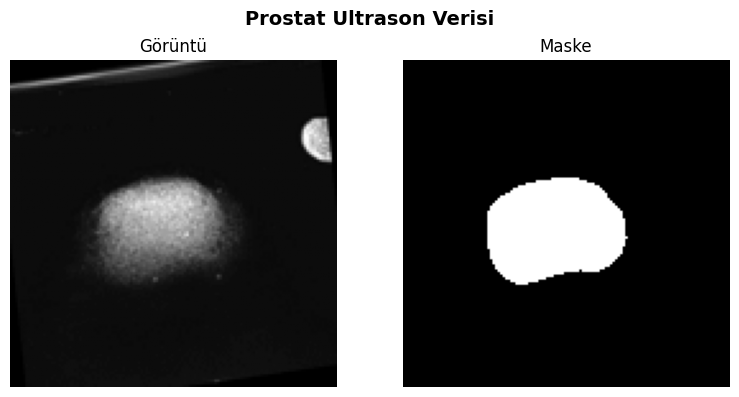

In [ ]:
# Örnek görüntü gösterimi
img, mask = full_dataset[0]
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img.squeeze(), cmap='gray');  axes[0].set_title('Görüntü');  axes[0].axis('off')
axes[1].imshow(mask.squeeze(), cmap='gray'); axes[1].set_title('Maske');    axes[1].axis('off')
plt.suptitle('Prostat Ultrason Verisi', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

## 3. Kayıp Fonksiyonları ve Metrikler

In [ ]:
def dice_loss(pred, target, smooth=1.0):
    pred  = torch.sigmoid(pred)
    inter = (pred * target).sum()
    return 1 - (2 * inter + smooth) / (pred.sum() + target.sum() + smooth)

def combined_loss(pred, target):
    bce = nn.BCEWithLogitsLoss()(pred, target)
    return 0.3 * bce + 0.7 * dice_loss(pred, target)

def dice_score(pred, target, smooth=1.0):
    pred  = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * target).sum()
    return (2 * inter + smooth) / (pred.sum() + target.sum() + smooth)

def iou_score(pred, target, smooth=1.0):
    pred  = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * target).sum()
    union = pred.sum() + target.sum() - inter
    return (inter + smooth) / (union + smooth)

## 4. Model Tanımlamaları

### 4.1 Ortak Decoder

In [ ]:
class SegDecoder(nn.Module):
    """Genel segmentasyon decoder'ı"""
    def __init__(self, in_dim=256, activation=nn.ReLU):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_dim, 128, 3, padding=1), activation(),
            nn.Conv2d(128,     64, 3, padding=1), activation(),
            nn.Conv2d(64,       1, 1)
        )

    def forward(self, x):
        B, N, D = x.shape
        H = W = int(N ** 0.5)
        x = x.transpose(1, 2).reshape(B, D, H, W)
        x = F.interpolate(x, scale_factor=16, mode='bilinear', align_corners=False)
        return self.conv(x)

### 4.2 ViT (Vision Transformer)

In [ ]:
class ViTSeg(nn.Module):
    """Vision Transformer Segmentasyon Modeli"""
    def __init__(self, img_size=128, patch_size=16, dim=256, depth=6, heads=8, activation=nn.ReLU):
        super().__init__()
        self.patch_embed  = nn.Conv2d(1, dim, kernel_size=patch_size, stride=patch_size)
        num_patches       = (img_size // patch_size) ** 2
        self.pos_embedding = nn.Parameter(torch.randn(1, num_patches, dim))
        enc_layer = nn.TransformerEncoderLayer(d_model=dim, nhead=heads,
                                               dim_feedforward=dim*4,
                                               activation='gelu', batch_first=True,
                                               dropout=0.1)
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=depth)
        self.decoder      = SegDecoder(dim, activation)

    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        x = x + self.pos_embedding
        x = self.transformer(x)
        return self.decoder(x)

### 4.3 Vanilla Transformer (Düz Transformer)

In [ ]:
class VanillaTransformerSeg(nn.Module):
    """
    Düz (Vanilla) Transformer Segmentasyonu.
    Orijinal 'Attention is All You Need' mimarisine sadık,
    class token veya learnable pos embedding YOK.
    """
    def __init__(self, img_size=128, patch_size=16, dim=256, depth=6, heads=8, activation=nn.ReLU):
        super().__init__()
        self.patch_size   = patch_size
        self.patch_embed  = nn.Conv2d(1, dim, kernel_size=patch_size, stride=patch_size)
        num_patches       = (img_size // patch_size) ** 2
        # Sinüzoidal pozisyon kodlaması (öğrenilmez)
        pe = self._sinusoidal_pe(num_patches, dim)
        self.register_buffer('pos_encoding', pe)
        enc_layer = nn.TransformerEncoderLayer(d_model=dim, nhead=heads,
                                               dim_feedforward=dim*4,
                                               activation='relu', batch_first=True,
                                               norm_first=False)  # Post-LN (orijinal gibi)
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=depth)
        self.decoder = SegDecoder(dim, activation)

    def _sinusoidal_pe(self, seq_len, d_model):
        pe  = torch.zeros(1, seq_len, d_model)
        pos = torch.arange(seq_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[0, :, 0::2] = torch.sin(pos * div)
        pe[0, :, 1::2] = torch.cos(pos * div[:d_model // 2])
        return pe

    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        x = x + self.pos_encoding
        x = self.transformer(x)
        return self.decoder(x)

### 4.4 MetaFormer Ailesi

> **MetaFormer** (Yu et al., 2022): "MetaFormer is Actually What You Need for Vision"
> Fikir: Transformer'daki Self-Attention'ı farklı 'token mixer'larla değiştir. Asıl gücün mimari çerçeveden geldiğini göster.

In [ ]:
# ── Ortak MetaFormer Bloğu ──────────────────────────────────────────────────
class MetaFormerBlock(nn.Module):
    """
    Genel MetaFormer bloğu.
    token_mixer: herhangi bir 'token mixing' modülü
    """
    def __init__(self, dim, token_mixer, mlp_ratio=4.0, activation=nn.GELU, drop=0.0):
        super().__init__()
        self.norm1  = nn.LayerNorm(dim)
        self.mixer  = token_mixer
        self.norm2  = nn.LayerNorm(dim)
        hidden      = int(dim * mlp_ratio)
        self.mlp    = nn.Sequential(
            nn.Linear(dim, hidden), activation(),
            nn.Dropout(drop),
            nn.Linear(hidden, dim), nn.Dropout(drop)
        )

    def forward(self, x):               # x: (B, N, D)
        x = x + self.mixer(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x


# ── Token Mixer'lar ─────────────────────────────────────────────────────────
class PoolMixer(nn.Module):
    """PoolFormer: Average Pooling token mixer"""
    def __init__(self, pool_size=3, **kwargs):
        super().__init__()
        self.pool = nn.AvgPool1d(pool_size, stride=1, padding=pool_size//2, count_include_pad=False)

    def forward(self, x):               # x: (B, N, D)
        return self.pool(x.transpose(1, 2)).transpose(1, 2) - x   # residual-free mixer


class AttentionMixer(nn.Module):
    """CaFormer: Causal/Standard Self-Attention mixer"""
    def __init__(self, dim, heads=8, **kwargs):
        super().__init__()
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)

    def forward(self, x):
        out, _ = self.attn(x, x, x)
        return out


class RandMixer(nn.Module):
    """RandFormer: Rastgele matris token mixer"""
    def __init__(self, seq_len, **kwargs):
        super().__init__()
        W = torch.randn(seq_len, seq_len)
        self.register_buffer('W', W / W.norm(dim=-1, keepdim=True))

    def forward(self, x):               # (B, N, D)
        return torch.einsum('mn,bnd->bmd', self.W, x)


class ConvMixer(nn.Module):
    """ConvFormer: Depthwise Conv token mixer"""
    def __init__(self, dim, kernel_size=7, **kwargs):
        super().__init__()
        self.dw_conv = nn.Conv1d(dim, dim, kernel_size, padding=kernel_size//2, groups=dim)

    def forward(self, x):               # (B, N, D)
        return self.dw_conv(x.transpose(1, 2)).transpose(1, 2)


class IdentityMixer(nn.Module):
    """IdentityFormer: Token mixing yok (sadece MLP)"""
    def forward(self, x):
        return torch.zeros_like(x)     # sıfır mixer → sadece MLP katkısı


class FNetMixer(nn.Module):
    """FNet: FFT tabanlı token mixer"""
    def forward(self, x):               # (B, N, D)
        return torch.fft.fft(torch.fft.fft(x, dim=-1), dim=-2).real


# ── MetaFormer Segmentasyon Modeli ──────────────────────────────────────────
class MetaFormerSeg(nn.Module):
    def __init__(self, mixer_type='pool', img_size=128, patch_size=16,
                 dim=256, depth=6, heads=8, activation=nn.GELU):
        super().__init__()
        self.patch_embed   = nn.Conv2d(1, dim, kernel_size=patch_size, stride=patch_size)
        num_patches        = (img_size // patch_size) ** 2
        self.pos_embedding = nn.Parameter(torch.randn(1, num_patches, dim))

        def make_mixer():
            if   mixer_type == 'pool':      return PoolMixer(pool_size=3)
            elif mixer_type == 'attention': return AttentionMixer(dim, heads)
            elif mixer_type == 'rand':      return RandMixer(num_patches)
            elif mixer_type == 'conv':      return ConvMixer(dim, kernel_size=7)
            elif mixer_type == 'identity':  return IdentityMixer()
            elif mixer_type == 'fnet':      return FNetMixer()
            else: raise ValueError(f'Bilinmeyen mixer: {mixer_type}')

        self.blocks  = nn.ModuleList([
            MetaFormerBlock(dim, make_mixer(), activation=activation) for _ in range(depth)
        ])
        self.norm    = nn.LayerNorm(dim)
        self.decoder = SegDecoder(dim, activation)

    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        x = x + self.pos_embedding
        for blk in self.blocks:
            x = blk(x)
        x = self.norm(x)
        return self.decoder(x)

print('✅ Tüm model sınıfları tanımlandı.')

✅ Tüm model sınıfları tanımlandı.


## 5. Eğitim ve Değerlendirme Fonksiyonları

In [ ]:
def dice_loss(pred, target, smooth=1.0):
    pred  = torch.sigmoid(pred)
    inter = (pred * target).sum()
    return 1 - (2 * inter + smooth) / (pred.sum() + target.sum() + smooth)

def combined_loss(pred, target):
    bce = nn.BCEWithLogitsLoss()(pred, target)
    return 0.3 * bce + 0.7 * dice_loss(pred, target)

def dice_score(pred, target, smooth=1.0):
    pred  = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * target).sum()
    return (2 * inter + smooth) / (pred.sum() + target.sum() + smooth)

def iou_score(pred, target, smooth=1.0):
    pred  = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * target).sum()
    union = pred.sum() + target.sum() - inter
    return (inter + smooth) / (union + smooth)

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        out  = model(imgs)
        loss = combined_loss(out, masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, total_dice, total_iou = 0.0, 0.0, 0.0
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        out = model(imgs)
        total_loss += combined_loss(out, masks).item()
        total_dice += dice_score(out, masks).item()
        total_iou  += iou_score(out, masks).item()
    n = len(loader)
    return total_loss / n, total_dice / n, total_iou / n


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def run_experiment(name, model, epochs=10, lr=1e-4, optimizer_name='Adam'):
    """Bir modeli eğitip sonuçları döndür."""
    torch.cuda.empty_cache() # Clear CUDA cache at the start of each experiment
    model = model.to(device)
    n_params = count_params(model)

    # Optimizer seçimi
    opt_map = {
        'Adam':     lambda: optim.Adam(model.parameters(),     lr=lr),
        'AdamW':    lambda: optim.AdamW(model.parameters(),    lr=lr, weight_decay=1e-2),
        'SGD':      lambda: optim.SGD(model.parameters(),      lr=lr, momentum=0.9, nesterov=True),
        'RMSprop':  lambda: optim.RMSprop(model.parameters(),  lr=lr, alpha=0.99),
        'Adagrad':  lambda: optim.Adagrad(model.parameters(),  lr=lr),
        'Adadelta': lambda: optim.Adadelta(model.parameters(), rho=0.9),
        'NAdam':    lambda: optim.NAdam(model.parameters(),    lr=lr),
    }
    optimizer = opt_map.get(optimizer_name, opt_map['Adam'])()
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {'train_loss': [], 'val_loss': [], 'val_dice': [], 'val_iou': []}
    best_dice = 0.0

    start = time.time()
    for epoch in range(epochs):
        tr_loss = train_one_epoch(model, train_loader, optimizer)
        vl_loss, vl_dice, vl_iou = evaluate(model, val_loader)
        scheduler.step()
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['val_dice'].append(vl_dice)
        history['val_iou'].append(vl_iou)
        if vl_dice > best_dice:
            best_dice = vl_dice
        if (epoch + 1) % 5 == 0:
            print(f'  [{name}] Epoch {epoch+1:2d}/{epochs} | '
                  f'Train Loss: {tr_loss:.4f} | Val Dice: {vl_dice:.4f} | IoU: {vl_iou:.4f}')

    elapsed = time.time() - start
    _, final_dice, final_iou = evaluate(model, val_loader)

    return {
        'name':       name,
        'params':     n_params,
        'best_dice':  best_dice,
        'final_dice': final_dice,
        'final_iou':  final_iou,
        'train_time': elapsed,
        'history':    history,
        'model':      model,
    }

print('✅ Eğitim fonksiyonları hazır.')

✅ Eğitim fonksiyonları hazır.


## 6. Deney 1 — Ana Mimari Karşılaştırması (20 Konfigürasyon)

| # | Model | Token Mixer | Notlar |
|---|-------|-------------|--------|
| 1 | ViT-Base | Self-Attention + learnable PE | depth=6, dim=256 |
| 2 | ViT-Small | Self-Attention + learnable PE | depth=4, dim=128 |
| 3 | ViT-Deep | Self-Attention + learnable PE | depth=8, dim=256 |
| 4 | ViT-Wide | Self-Attention + learnable PE | depth=6, dim=512 |
| 5 | Vanilla Transformer | Self-Attention + sinusoidal PE | Post-LN |
| 6 | Vanilla Transformer Deep | Self-Attention + sinusoidal PE | depth=8 |
| 7 | MetaFormer-Pool | AvgPool1d | PoolFormer |
| 8 | MetaFormer-Pool-Deep | AvgPool1d | depth=8 |
| 9 | MetaFormer-Attn (CaFormer) | MHSA | CaFormer |
| 10 | MetaFormer-Rand (RandFormer) | Random Matrix | |
| 11 | MetaFormer-Conv (ConvFormer) | DepthwiseConv | |
| 12 | MetaFormer-Identity | Zero mixer | Sadece MLP |
| 13 | MetaFormer-FNet | FFT | FNet |
| 14 | MetaFormer-Pool GELU | AvgPool + GELU decoder | |
| 15 | MetaFormer-Attn GELU | MHSA + GELU decoder | |
| 16 | ViT + Mish | Mish aktivasyon | |
| 17 | ViT + SiLU | SiLU aktivasyon | |
| 18 | ViT Adam | Adam optimizer | |
| 19 | ViT AdamW | AdamW optimizer | |
| 20 | ViT SGD | SGD+momentum optimizer | |

In [ ]:
EPOCHS = 15   # Süreyi kısaltmak için; tam eğitim için 30-50 yapın

experiments_config = [
    # (isim, model_fonksiyonu)
    ('1_ViT_Base',             lambda: ViTSeg(dim=256, depth=6, heads=8)),
    ('2_ViT_Small',            lambda: ViTSeg(dim=128, depth=4, heads=4)),
    ('3_ViT_Deep',             lambda: ViTSeg(dim=256, depth=8, heads=8)),
    ('4_ViT_Wide',             lambda: ViTSeg(dim=512, depth=6, heads=8)),
    ('5_Vanilla_Trans',        lambda: VanillaTransformerSeg(dim=256, depth=6, heads=8)),
    ('6_Vanilla_Deep',         lambda: VanillaTransformerSeg(dim=256, depth=8, heads=8)),
    ('7_MetaPool',             lambda: MetaFormerSeg('pool',     dim=256, depth=6)),
    ('8_MetaPool_Deep',        lambda: MetaFormerSeg('pool',     dim=256, depth=8)),
    ('9_MetaAttn_CaFormer',    lambda: MetaFormerSeg('attention',dim=256, depth=6, heads=8)),
    ('10_MetaRand_RandFormer', lambda: MetaFormerSeg('rand',     dim=256, depth=6)),
    ('11_MetaConv_ConvFormer', lambda: MetaFormerSeg('conv',     dim=256, depth=6)),
    ('12_MetaIdentity',        lambda: MetaFormerSeg('identity', dim=256, depth=6)),
    ('13_MetaFNet',            lambda: MetaFormerSeg('fnet',     dim=256, depth=6)),
    ('14_MetaPool_GELU',       lambda: MetaFormerSeg('pool',     dim=256, depth=6, activation=nn.GELU)),
    ('15_MetaAttn_GELU',       lambda: MetaFormerSeg('attention',dim=256, depth=6, heads=8, activation=nn.GELU)),
    ('16_ViT_Mish',            lambda: ViTSeg(dim=256, depth=6, activation=nn.Mish)),
    ('17_ViT_SiLU',            lambda: ViTSeg(dim=256, depth=6, activation=nn.SiLU)),
    ('18_ViT_Adam',            lambda: ViTSeg(dim=256, depth=6)),   # Adam default
    ('19_ViT_AdamW',           lambda: ViTSeg(dim=256, depth=6)),   # AdamW
    ('20_ViT_SGD',             lambda: ViTSeg(dim=256, depth=6)),   # SGD
]

optimizer_map = defaultdict(lambda: 'Adam')
optimizer_map['18_ViT_Adam']  = 'Adam'
optimizer_map['19_ViT_AdamW'] = 'AdamW'
optimizer_map['20_ViT_SGD']   = 'SGD'

all_results = []

for name, model_fn in experiments_config:
    print(f'\n🚀 [{name}] eğitimi başlıyor...')
    model = model_fn()
    opt   = optimizer_map[name]
    res   = run_experiment(name, model, epochs=EPOCHS, lr=1e-4, optimizer_name=opt)
    all_results.append(res)
    print(f'   ✅ Bitti | Dice: {res["final_dice"]:.4f} | IoU: {res["final_iou"]:.4f} | '
          f'Params: {res["params"]/1e6:.2f}M | Süre: {res["train_time"]:.1f}s')

print('\n🎉 Tüm deneyler tamamlandı!')


🚀 [1_ViT_Base] eğitimi başlıyor...
  [1_ViT_Base] Epoch  5/15 | Train Loss: 0.1007 | Val Dice: 0.9491 | IoU: 0.9041
  [1_ViT_Base] Epoch 10/15 | Train Loss: 0.0611 | Val Dice: 0.9698 | IoU: 0.9414
  [1_ViT_Base] Epoch 15/15 | Train Loss: 0.0450 | Val Dice: 0.9731 | IoU: 0.9477
   ✅ Bitti | Dice: 0.9731 | IoU: 0.9477 | Params: 5.19M | Süre: 336.5s

🚀 [2_ViT_Small] eğitimi başlıyor...
  [2_ViT_Small] Epoch  5/15 | Train Loss: 0.1087 | Val Dice: 0.9434 | IoU: 0.8936
  [2_ViT_Small] Epoch 10/15 | Train Loss: 0.0883 | Val Dice: 0.9555 | IoU: 0.9155
  [2_ViT_Small] Epoch 15/15 | Train Loss: 0.0788 | Val Dice: 0.9591 | IoU: 0.9218
   ✅ Bitti | Dice: 0.9591 | IoU: 0.9218 | Params: 1.06M | Süre: 319.1s

🚀 [3_ViT_Deep] eğitimi başlıyor...
  [3_ViT_Deep] Epoch  5/15 | Train Loss: 0.1026 | Val Dice: 0.9453 | IoU: 0.8970
  [3_ViT_Deep] Epoch 10/15 | Train Loss: 0.0551 | Val Dice: 0.9721 | IoU: 0.9458
  [3_ViT_Deep] Epoch 15/15 | Train Loss: 0.0429 | Val Dice: 0.9750 | IoU: 0.9514
   ✅ Bitti | Dice

## 7. Deney 2 — Optimizer Karşılaştırması

In [ ]:
optimizer_experiments = []
optimizers_to_test = ['Adam', 'AdamW', 'SGD', 'RMSprop', 'Adagrad', 'Adadelta', 'NAdam']

print('\n📊 Optimizer Karşılaştırması (ViT-Base üzerinde)\n')
for opt_name in optimizers_to_test:
    print(f'  Optimizer: {opt_name}')
    model = ViTSeg(dim=256, depth=6, heads=8).to(device)
    res   = run_experiment(f'Opt_{opt_name}', model, epochs=EPOCHS, lr=1e-4, optimizer_name=opt_name)
    optimizer_experiments.append(res)
    print(f'  Dice: {res["final_dice"]:.4f} | IoU: {res["final_iou"]:.4f}')

print('\n✅ Optimizer deneyleri tamamlandı!')


📊 Optimizer Karşılaştırması (ViT-Base üzerinde)

  Optimizer: Adam
  [Opt_Adam] Epoch  5/15 | Train Loss: 0.0948 | Val Dice: 0.9465 | IoU: 0.8989
  [Opt_Adam] Epoch 10/15 | Train Loss: 0.0529 | Val Dice: 0.9706 | IoU: 0.9430
  [Opt_Adam] Epoch 15/15 | Train Loss: 0.0436 | Val Dice: 0.9741 | IoU: 0.9496
  Dice: 0.9741 | IoU: 0.9496
  Optimizer: AdamW
  [Opt_AdamW] Epoch  5/15 | Train Loss: 0.1003 | Val Dice: 0.9512 | IoU: 0.9077
  [Opt_AdamW] Epoch 10/15 | Train Loss: 0.0531 | Val Dice: 0.9660 | IoU: 0.9345
  [Opt_AdamW] Epoch 15/15 | Train Loss: 0.0436 | Val Dice: 0.9744 | IoU: 0.9502
  Dice: 0.9744 | IoU: 0.9502
  Optimizer: SGD
  [Opt_SGD] Epoch  5/15 | Train Loss: 0.5451 | Val Dice: 0.6160 | IoU: 0.4477
  [Opt_SGD] Epoch 10/15 | Train Loss: 0.4788 | Val Dice: 0.7722 | IoU: 0.6318
  [Opt_SGD] Epoch 15/15 | Train Loss: 0.4540 | Val Dice: 0.7873 | IoU: 0.6519
  Dice: 0.7873 | IoU: 0.6519
  Optimizer: RMSprop
  [Opt_RMSprop] Epoch  5/15 | Train Loss: 0.1005 | Val Dice: 0.9481 | IoU: 0.

## 8. Deney 3 — Aktivasyon Fonksiyonu Karşılaştırması

In [ ]:
activation_experiments = []

activations_to_test = {
    'ReLU':       nn.ReLU,
    'GELU':       nn.GELU,
    'SiLU':       nn.SiLU,
    'Mish':       nn.Mish,
    'ELU':        nn.ELU,
    'LeakyReLU':  nn.LeakyReLU,
    'Hardswish':  nn.Hardswish,
    'PReLU':      nn.PReLU,
}

print('\n📊 Aktivasyon Fonksiyonu Karşılaştırması (MetaFormer-Pool üzerinde)\n')
for act_name, act_cls in activations_to_test.items():
    print(f'  Aktivasyon: {act_name}')
    model = MetaFormerSeg('pool', dim=256, depth=6, activation=act_cls).to(device)
    res   = run_experiment(f'Act_{act_name}', model, epochs=EPOCHS, lr=1e-4)
    activation_experiments.append(res)
    print(f'  Dice: {res["final_dice"]:.4f} | IoU: {res["final_iou"]:.4f}')

print('\n✅ Aktivasyon deneyleri tamamlandı!')


📊 Aktivasyon Fonksiyonu Karşılaştırması (MetaFormer-Pool üzerinde)

  Aktivasyon: ReLU
  [Act_ReLU] Epoch  5/15 | Train Loss: 0.2439 | Val Dice: 0.8450 | IoU: 0.7326
  [Act_ReLU] Epoch 10/15 | Train Loss: 0.1880 | Val Dice: 0.8876 | IoU: 0.7990
  [Act_ReLU] Epoch 15/15 | Train Loss: 0.1735 | Val Dice: 0.8983 | IoU: 0.8164
  Dice: 0.8983 | IoU: 0.8164
  Aktivasyon: GELU
  [Act_GELU] Epoch  5/15 | Train Loss: 0.2317 | Val Dice: 0.8672 | IoU: 0.7664
  [Act_GELU] Epoch 10/15 | Train Loss: 0.1705 | Val Dice: 0.9004 | IoU: 0.8198
  [Act_GELU] Epoch 15/15 | Train Loss: 0.1579 | Val Dice: 0.9073 | IoU: 0.8314
  Dice: 0.9073 | IoU: 0.8314
  Aktivasyon: SiLU
  [Act_SiLU] Epoch  5/15 | Train Loss: 0.2372 | Val Dice: 0.8591 | IoU: 0.7538
  [Act_SiLU] Epoch 10/15 | Train Loss: 0.1874 | Val Dice: 0.8858 | IoU: 0.7959
  [Act_SiLU] Epoch 15/15 | Train Loss: 0.1594 | Val Dice: 0.9055 | IoU: 0.8283
  Dice: 0.9055 | IoU: 0.8283
  Aktivasyon: Mish
  [Act_Mish] Epoch  5/15 | Train Loss: 0.2291 | Val Dice:

## 9. Sonuçların Toplanması ve Analizi

In [ ]:
def print_table(results, title='Sonuçlar'):
    print(f'\n{'='*80}')
    print(f' {title}')
    print(f'{'='*80}')
    print(f'{"Model":<32} {"Dice":>8} {"IoU":>8} {"Params":>10} {"Süre (s)":>10}')
    print('-'*80)
    for r in sorted(results, key=lambda x: x['final_dice'], reverse=True):
        print(f'{r["name"]:<32} {r["final_dice"]:>8.4f} {r["final_iou"]:>8.4f} '
              f'{r["params"]/1e6:>9.2f}M {r["train_time"]:>9.1f}s')
    print('='*80)

print_table(all_results,            'Ana Mimari Karşılaştırması (20 Model)')
print_table(optimizer_experiments,  'Optimizer Karşılaştırması')
print_table(activation_experiments, 'Aktivasyon Fonksiyonu Karşılaştırması')


 Ana Mimari Karşılaştırması (20 Model)
Model                                Dice      IoU     Params   Süre (s)
--------------------------------------------------------------------------------
4_ViT_Wide                         0.9809   0.9626     19.74M     361.6s
5_Vanilla_Trans                    0.9786   0.9581      5.17M     328.1s
15_MetaAttn_GELU                   0.9775   0.9560      5.19M     305.7s
6_Vanilla_Deep                     0.9768   0.9548      6.75M     320.9s
16_ViT_Mish                        0.9755   0.9522      5.19M     306.4s
3_ViT_Deep                         0.9750   0.9514      6.77M     331.3s
19_ViT_AdamW                       0.9750   0.9512      5.19M     315.0s
17_ViT_SiLU                        0.9742   0.9498      5.19M     307.8s
9_MetaAttn_CaFormer                0.9742   0.9498      5.19M     309.8s
18_ViT_Adam                        0.9740   0.9494      5.19M     309.4s
1_ViT_Base                         0.9731   0.9477      5.19M     336.5s
11_

## 10. Görselleştirmeler

### 10.1 Ana Model Karşılaştırma Bar Grafikleri

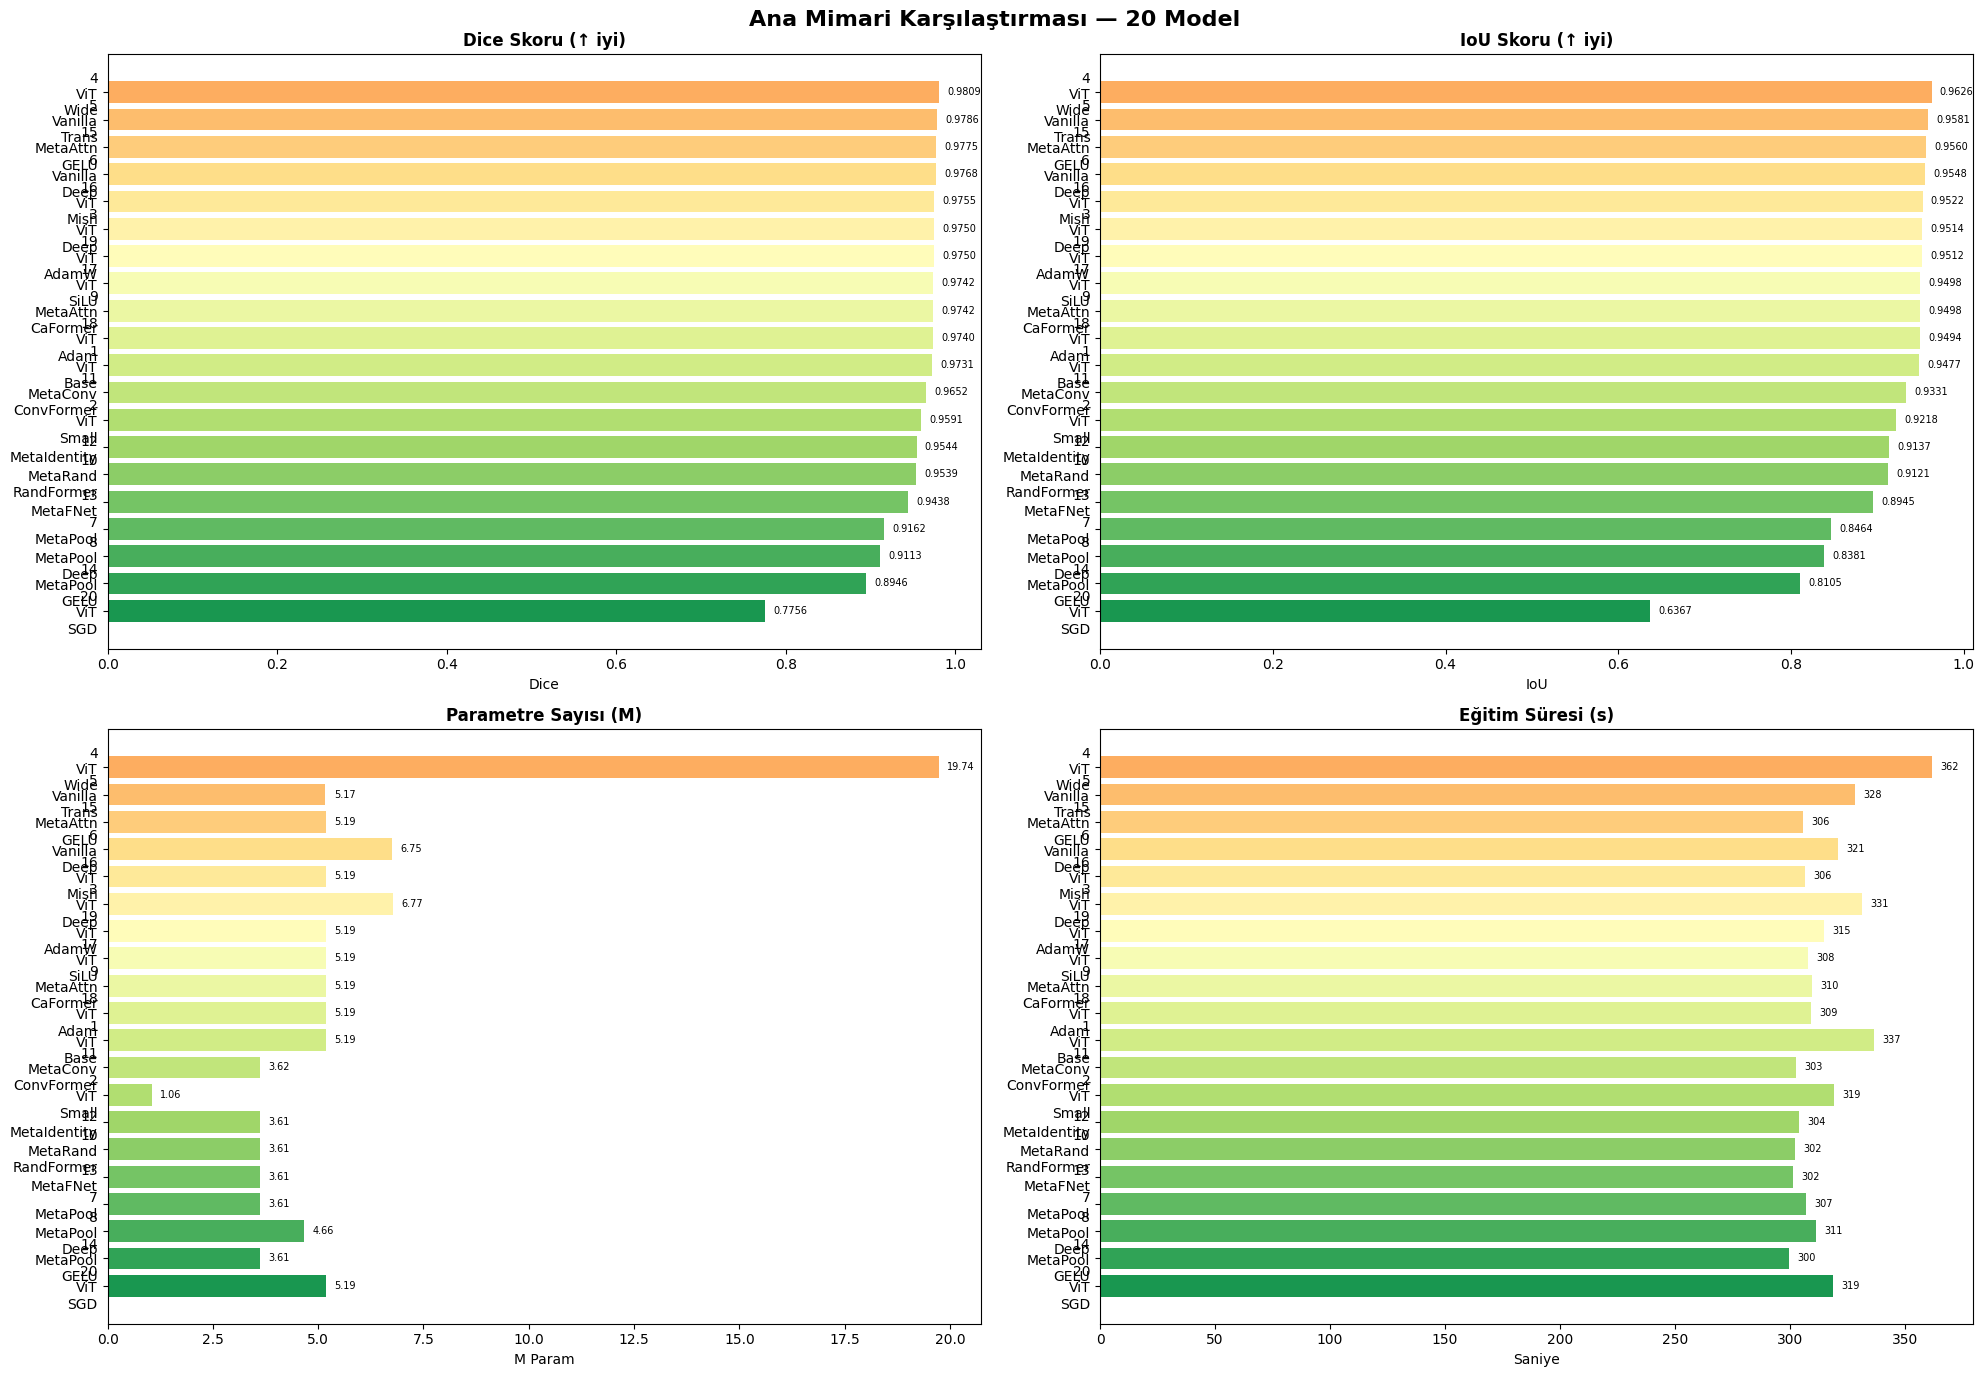

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
fig.suptitle('Ana Mimari Karşılaştırması — 20 Model', fontsize=16, fontweight='bold')

res_sorted_dice = sorted(all_results, key=lambda x: x['final_dice'], reverse=True)
names  = [r['name'].replace('_', '\n') for r in res_sorted_dice]
dices  = [r['final_dice'] for r in res_sorted_dice]
ious   = [r['final_iou']  for r in res_sorted_dice]
params = [r['params']/1e6 for r in res_sorted_dice]
times  = [r['train_time'] for r in res_sorted_dice]

colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(names)))

for ax, vals, title, ylabel, fmt in zip(
    axes.flat,
    [dices, ious, params, times],
    ['Dice Skoru (↑ iyi)', 'IoU Skoru (↑ iyi)', 'Parametre Sayısı (M)', 'Eğitim Süresi (s)'],
    ['Dice', 'IoU', 'M Param', 'Saniye'],
    ['.4f', '.4f', '.2f', '.0f']
):
    bars = ax.barh(names, vals, color=colors)
    ax.set_xlabel(ylabel)
    ax.set_title(title, fontweight='bold')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_width() + max(vals)*0.01, bar.get_y() + bar.get_height()/2,
                f'{v:{fmt}}', va='center', fontsize=7)
    ax.invert_yaxis()

plt.tight_layout()
plt.savefig('mimari_karsilastirma.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.2 Eğitim Eğrileri — En İyi 5 Model

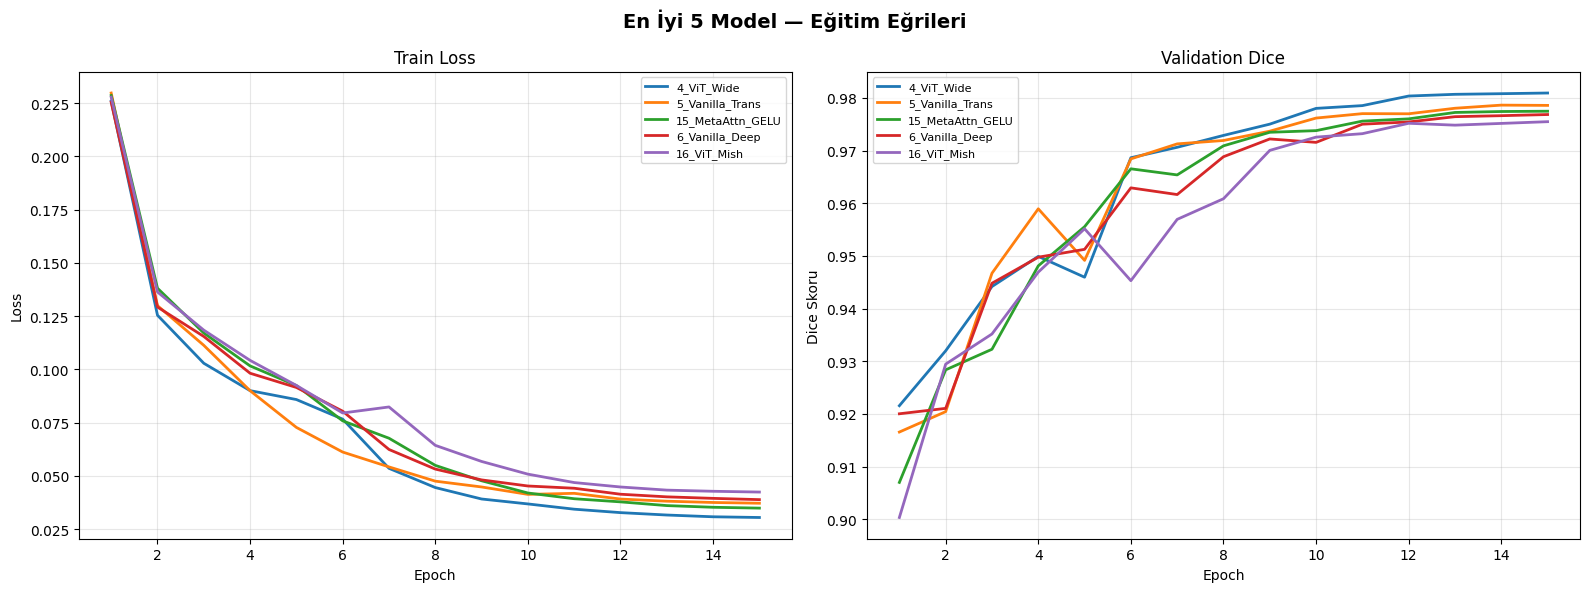

In [ ]:
top5 = sorted(all_results, key=lambda x: x['final_dice'], reverse=True)[:5]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('En İyi 5 Model — Eğitim Eğrileri', fontsize=14, fontweight='bold')

for r in top5:
    h = r['history']
    ep = range(1, len(h['train_loss']) + 1)
    axes[0].plot(ep, h['train_loss'], label=r['name'], linewidth=2)
    axes[1].plot(ep, h['val_dice'],   label=r['name'], linewidth=2)

axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss');      axes[0].set_title('Train Loss')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Dice Skoru'); axes[1].set_title('Validation Dice')
for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('egitim_egrileri_top5.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.3 Optimizer Karşılaştırma Grafikleri

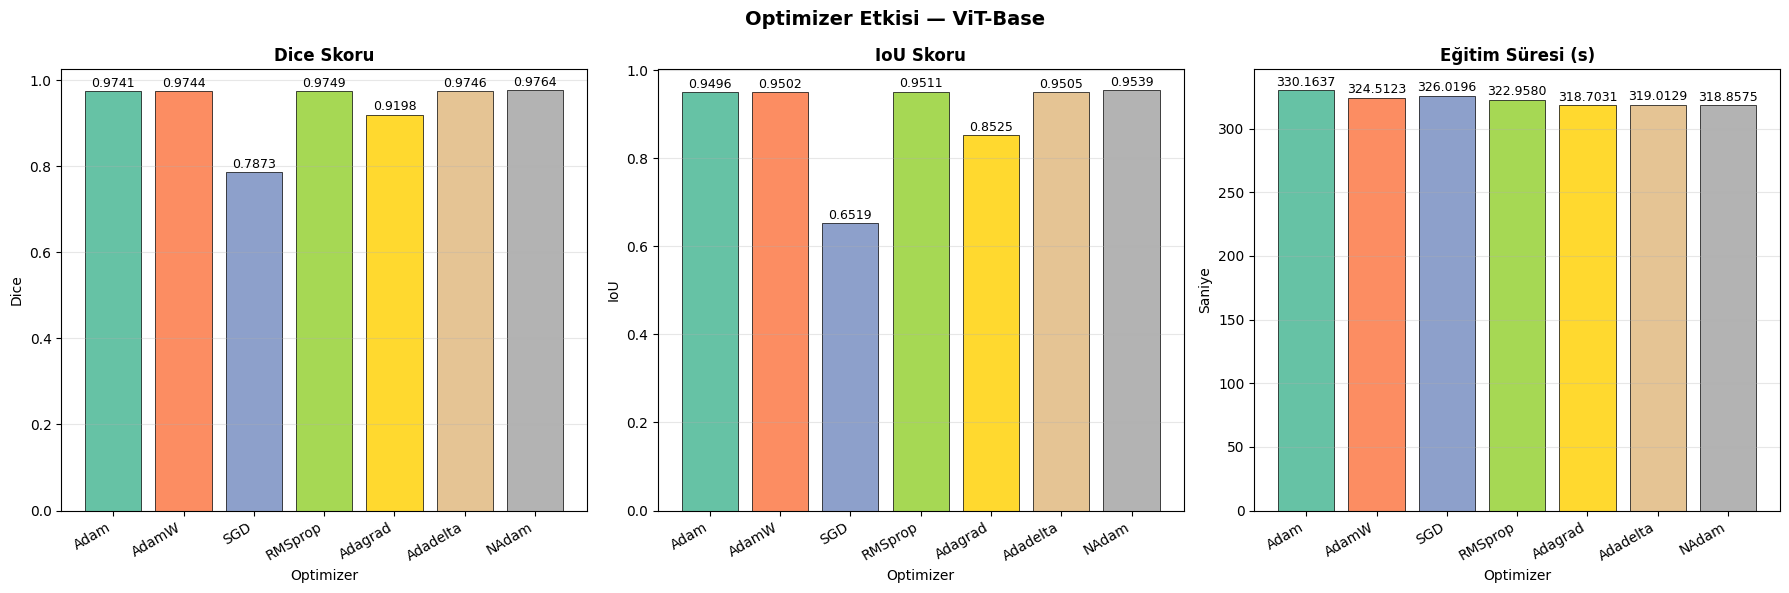

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Optimizer Etkisi — ViT-Base', fontsize=14, fontweight='bold')

opt_names  = [r['name'].replace('Opt_', '') for r in optimizer_experiments]
opt_dices  = [r['final_dice'] for r in optimizer_experiments]
opt_ious   = [r['final_iou']  for r in optimizer_experiments]
opt_times  = [r['train_time'] for r in optimizer_experiments]

palette = plt.cm.Set2(np.linspace(0, 1, len(opt_names)))

for ax, vals, title, ylabel in zip(
    axes,
    [opt_dices, opt_ious, opt_times],
    ['Dice Skoru', 'IoU Skoru', 'Eğitim Süresi (s)'],
    ['Dice', 'IoU', 'Saniye']
):
    bars = ax.bar(opt_names, vals, color=palette, edgecolor='black', linewidth=0.5)
    ax.set_xlabel('Optimizer'); ax.set_ylabel(ylabel); ax.set_title(title, fontweight='bold')
    ax.set_xticklabels(opt_names, rotation=30, ha='right')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
                f'{v:.4f}', ha='center', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('optimizer_karsilastirma.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.4 Aktivasyon Fonksiyonu Karşılaştırma Grafikleri

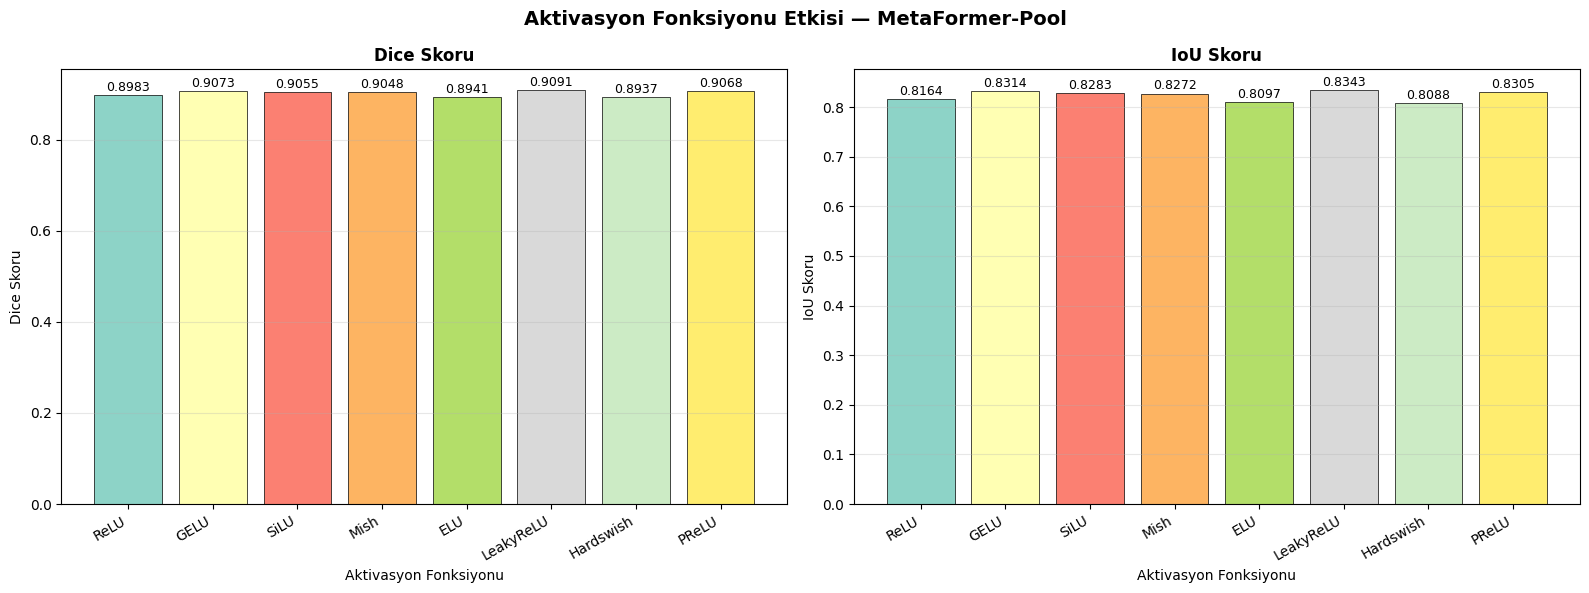

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Aktivasyon Fonksiyonu Etkisi — MetaFormer-Pool', fontsize=14, fontweight='bold')

act_names = [r['name'].replace('Act_', '') for r in activation_experiments]
act_dices = [r['final_dice'] for r in activation_experiments]
act_ious  = [r['final_iou']  for r in activation_experiments]

palette2 = plt.cm.Set3(np.linspace(0, 1, len(act_names)))

for ax, vals, title in zip(axes, [act_dices, act_ious], ['Dice Skoru', 'IoU Skoru']):
    bars = ax.bar(act_names, vals, color=palette2, edgecolor='black', linewidth=0.5)
    ax.set_xlabel('Aktivasyon Fonksiyonu'); ax.set_ylabel(title)
    ax.set_title(title, fontweight='bold')
    ax.set_xticklabels(act_names, rotation=30, ha='right')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
                f'{v:.4f}', ha='center', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('aktivasyon_karsilastirma.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.5 Optimizer Eğitim Eğrileri

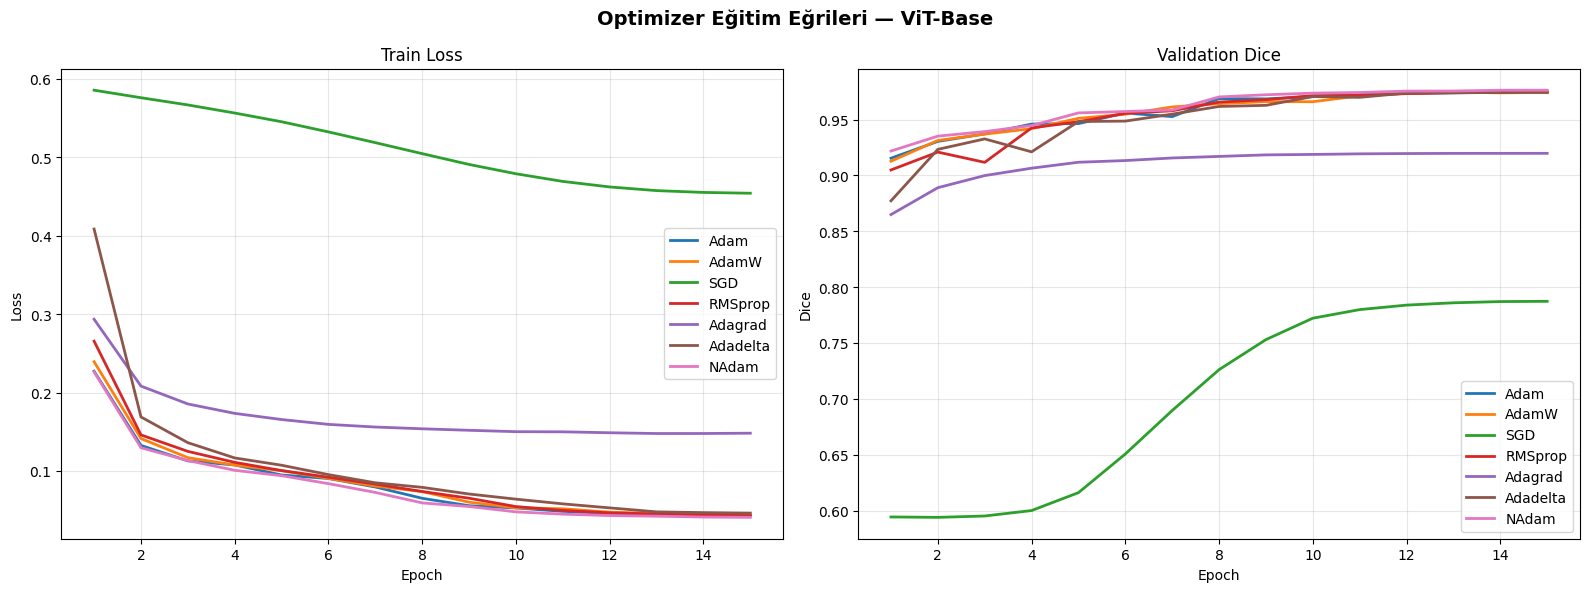

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Optimizer Eğitim Eğrileri — ViT-Base', fontsize=14, fontweight='bold')

for r in optimizer_experiments:
    h  = r['history']
    ep = range(1, len(h['train_loss']) + 1)
    label = r['name'].replace('Opt_', '')
    axes[0].plot(ep, h['train_loss'], label=label, linewidth=2)
    axes[1].plot(ep, h['val_dice'],   label=label, linewidth=2)

axes[0].set_title('Train Loss');       axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[1].set_title('Validation Dice');  axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Dice')
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('optimizer_egitim_egrileri.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.6 Aktivasyon Eğitim Eğrileri

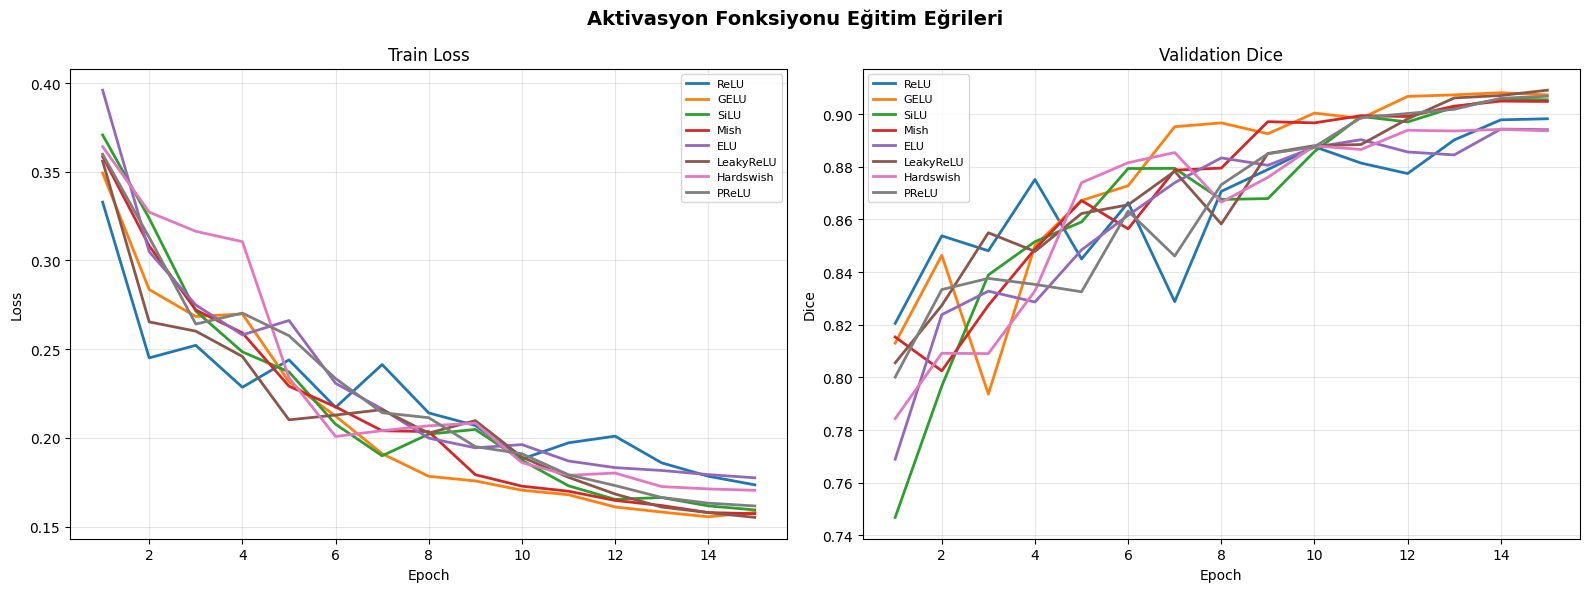

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Aktivasyon Fonksiyonu Eğitim Eğrileri', fontsize=14, fontweight='bold')

for r in activation_experiments:
    h  = r['history']
    ep = range(1, len(h['train_loss']) + 1)
    label = r['name'].replace('Act_', '')
    axes[0].plot(ep, h['train_loss'], label=label, linewidth=2)
    axes[1].plot(ep, h['val_dice'],   label=label, linewidth=2)

axes[0].set_title('Train Loss');       axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[1].set_title('Validation Dice');  axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Dice')
for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('aktivasyon_egitim_egrileri.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.7 Params vs Dice Scatter (Verimlilik Analizi)

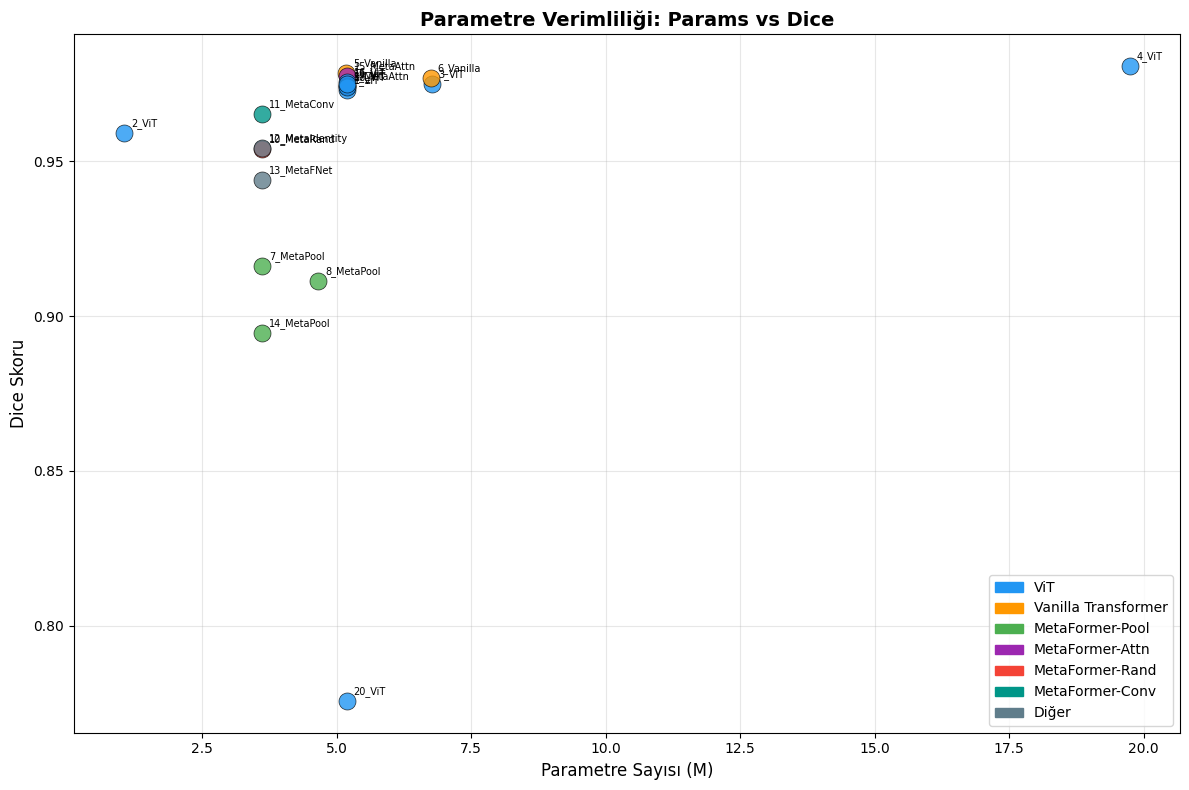

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))

# Model tipine göre renk
color_map = {}
for r in all_results:
    name = r['name']
    if   'ViT'      in name: color_map[name] = '#2196F3'   # mavi
    elif 'Vanilla'  in name: color_map[name] = '#FF9800'   # turuncu
    elif 'MetaPool' in name: color_map[name] = '#4CAF50'   # yeşil
    elif 'MetaAttn' in name: color_map[name] = '#9C27B0'   # mor
    elif 'MetaRand' in name: color_map[name] = '#F44336'   # kırmızı
    elif 'MetaConv' in name: color_map[name] = '#009688'   # teal
    else:                    color_map[name] = '#607D8B'   # gri

for r in all_results:
    ax.scatter(r['params']/1e6, r['final_dice'],
               c=color_map[r['name']], s=150, alpha=0.8, edgecolors='black', linewidth=0.5)
    ax.annotate(r['name'].split('_')[0] + '_' + r['name'].split('_')[1],
                (r['params']/1e6, r['final_dice']),
                textcoords='offset points', xytext=(5, 5), fontsize=7)

# Legand
legend_items = [
    mpatches.Patch(color='#2196F3', label='ViT'),
    mpatches.Patch(color='#FF9800', label='Vanilla Transformer'),
    mpatches.Patch(color='#4CAF50', label='MetaFormer-Pool'),
    mpatches.Patch(color='#9C27B0', label='MetaFormer-Attn'),
    mpatches.Patch(color='#F44336', label='MetaFormer-Rand'),
    mpatches.Patch(color='#009688', label='MetaFormer-Conv'),
    mpatches.Patch(color='#607D8B', label='Diğer'),
]
ax.legend(handles=legend_items, loc='lower right')
ax.set_xlabel('Parametre Sayısı (M)', fontsize=12)
ax.set_ylabel('Dice Skoru', fontsize=12)
ax.set_title('Parametre Verimliliği: Params vs Dice', fontsize=14, fontweight='bold')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('params_vs_dice.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.8 Nitel Görsel Karşılaştırma — En İyi 5 vs En Kötü 2

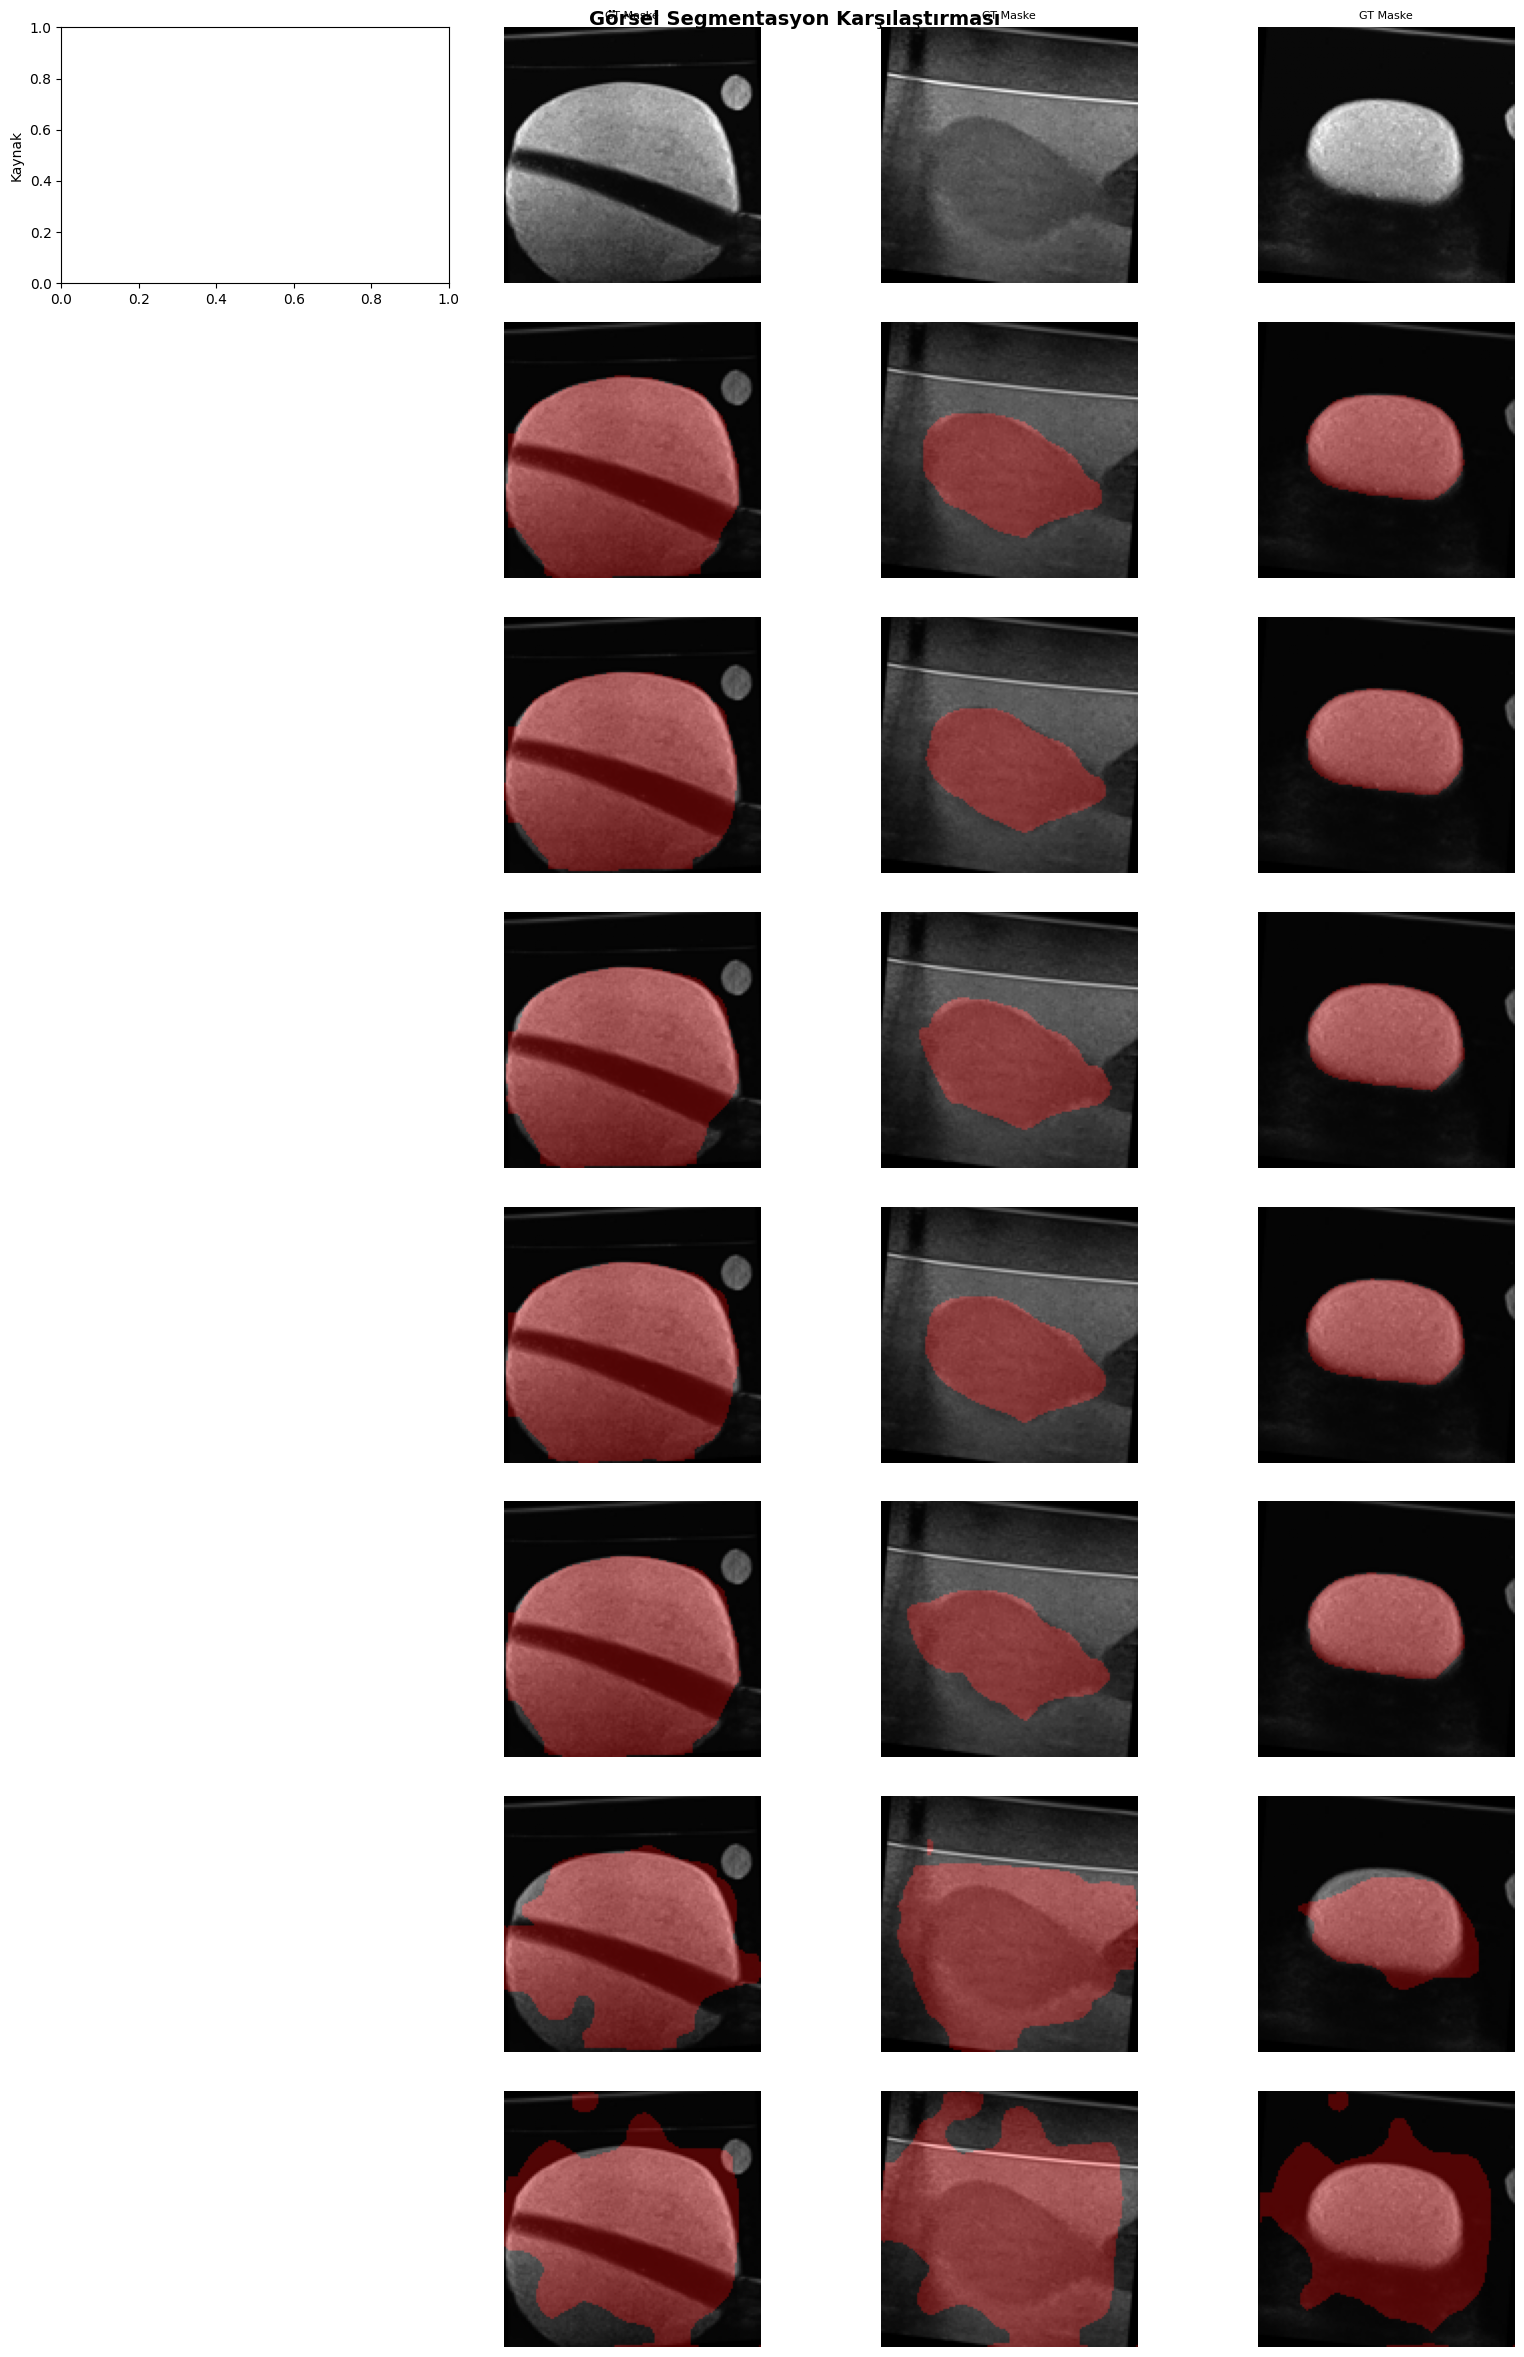

In [ ]:
sorted_results = sorted(all_results, key=lambda x: x['final_dice'], reverse=True)
showcase_models = sorted_results[:5] + sorted_results[-2:]

num_samples = 3
sample_indices = [0, len(val_ds)//2, len(val_ds)-1]

fig, axes = plt.subplots(len(showcase_models) + 1, num_samples + 1,
                          figsize=(4*(num_samples+1), 3*(len(showcase_models)+1)))

fig.suptitle('Görsel Segmentasyon Karşılaştırması', fontsize=14, fontweight='bold')

axes[0, 0].set_ylabel('Kaynak', fontsize=10)
for j, idx in enumerate(sample_indices):
    img, mask = val_ds[idx]
    axes[0, j+1].imshow(img.squeeze(), cmap='gray')
    axes[0, j+1].set_title(f'GT Maske', fontsize=8)
    axes[0, j+1].axis('off')

for i, res in enumerate(showcase_models):
    model = res['model']
    model.eval()
    axes[i+1, 0].set_ylabel(f'{res["name"][2:]}\nDice={res["final_dice"]:.3f}', fontsize=7)
    axes[i+1, 0].axis('off')
    for j, idx in enumerate(sample_indices):
        img, mask = val_ds[idx]
        with torch.no_grad():
            pred = torch.sigmoid(model(img.unsqueeze(0).to(device))).squeeze().cpu()
        pred_bin = (pred > 0.5).float()
        # RGB overlay
        overlay = np.stack([img.squeeze()]*3, axis=-1)
        overlay[..., 0] += 0.3 * pred_bin.numpy()  # kırmızı = tahmin
        overlay = np.clip(overlay, 0, 1)
        axes[i+1, j+1].imshow(overlay)
        axes[i+1, j+1].axis('off')

plt.tight_layout()
plt.savefig('gorsel_karsilastirma.png', dpi=120, bbox_inches='tight')
plt.show()

## 11. Özet Tablo ve Final Raporu

In [ ]:
print('\n' + '='*90)
print('  KAPSAMLI KARŞILAŞTIRMA RAPORU — Prostat Ultrason Segmentasyonu')
print('='*90)

print('\n📌 ANA MİMARİ KARŞILAŞTIRMASI (20 Model) — Dice Sıralı')
print_table(all_results, '')

print('\n📌 OPTİMİZER ANALİZİ')
print_table(optimizer_experiments, '')

print('\n📌 AKTİVASYON FONKSİYONU ANALİZİ')
print_table(activation_experiments, '')

# En iyi sonuçlar
best_model = max(all_results, key=lambda x: x['final_dice'])
best_opt   = max(optimizer_experiments, key=lambda x: x['final_dice'])
best_act   = max(activation_experiments, key=lambda x: x['final_dice'])

print(f'\n🏆 EN İYİ MODEL:       {best_model["name"]} → Dice: {best_model["final_dice"]:.4f}')
print(f'🏆 EN İYİ OPTİMİZER:   {best_opt["name"]}  → Dice: {best_opt["final_dice"]:.4f}')
print(f'🏆 EN İYİ AKTİVASYON:  {best_act["name"]} → Dice: {best_act["final_dice"]:.4f}')

# Hafızada tutulan tüm sonuçları JSON olarak kaydet
def serialize(results):
    out = []
    for r in results:
        d = {k: v for k, v in r.items() if k != 'model'}
        out.append(d)
    return out

all_data = {
    'main_experiments':       serialize(all_results),
    'optimizer_experiments':  serialize(optimizer_experiments),
    'activation_experiments': serialize(activation_experiments),
}
with open('experiment_results.json', 'w', encoding='utf-8') as f:
    json.dump(all_data, f, indent=2, ensure_ascii=False)

print('\n💾 Tüm sonuçlar experiment_results.json dosyasına kaydedildi.')


  KAPSAMLI KARŞILAŞTIRMA RAPORU — Prostat Ultrason Segmentasyonu

📌 ANA MİMARİ KARŞILAŞTIRMASI (20 Model) — Dice Sıralı

 
Model                                Dice      IoU     Params   Süre (s)
--------------------------------------------------------------------------------
4_ViT_Wide                         0.9809   0.9626     19.74M     361.6s
5_Vanilla_Trans                    0.9786   0.9581      5.17M     328.1s
15_MetaAttn_GELU                   0.9775   0.9560      5.19M     305.7s
6_Vanilla_Deep                     0.9768   0.9548      6.75M     320.9s
16_ViT_Mish                        0.9755   0.9522      5.19M     306.4s
3_ViT_Deep                         0.9750   0.9514      6.77M     331.3s
19_ViT_AdamW                       0.9750   0.9512      5.19M     315.0s
17_ViT_SiLU                        0.9742   0.9498      5.19M     307.8s
9_MetaAttn_CaFormer                0.9742   0.9498      5.19M     309.8s
18_ViT_Adam                        0.9740   0.9494      5.19M    

## 12. MetaFormer Token Mixer Karşılaştırması — Özet Grafik

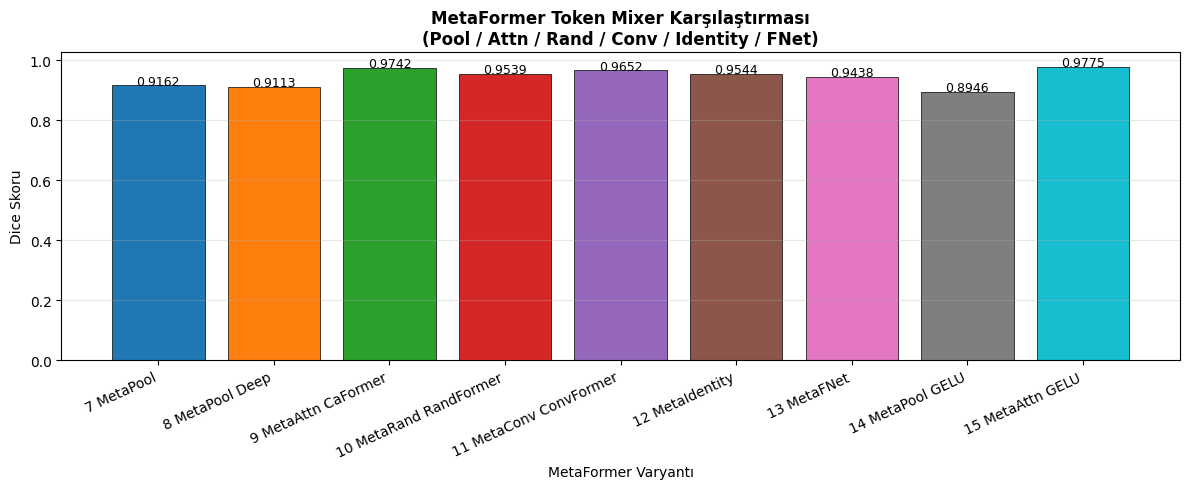


✅ Tüm analizler ve grafikler tamamlandı!


In [ ]:
# Sadece MetaFormer modelleri filtrele
meta_results = [r for r in all_results if 'Meta' in r['name']]

fig, ax = plt.subplots(figsize=(12, 5))
names  = [r['name'].replace('_', ' ') for r in meta_results]
dices  = [r['final_dice'] for r in meta_results]

bars = ax.bar(names, dices, color=plt.cm.tab10(np.linspace(0, 0.9, len(names))),
              edgecolor='black', linewidth=0.5)
for bar, v in zip(bars, dices):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{v:.4f}', ha='center', fontsize=9)

ax.set_xlabel('MetaFormer Varyantı')
ax.set_ylabel('Dice Skoru')
ax.set_title('MetaFormer Token Mixer Karşılaştırması\n(Pool / Attn / Rand / Conv / Identity / FNet)',
             fontweight='bold')
ax.set_xticklabels(names, rotation=25, ha='right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('metaformer_karsilastirma.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n✅ Tüm analizler ve grafikler tamamlandı!')

# 🔬 20 MİMARİ - 7 OPTİMİZER KARŞILAŞTIRMASI
## Prostat Ultrason Segmentasyonu

Bu kısımda 20 farklı mimari üzerinde 7 farklı optimizerı karşılaştırdım.
**Toplam deney sayısı:** 140 (20 × 7)

**Mimariler:**
- 4 ViT (Vision Transformer)
- 3 PoolFormer
- 3 CaFormer
- 2 RandFormer
- 2 ConvFormer
- 1 Vanilla Transformer

**Optimizerlar:**
Adam, AdamW, SGD, RMSprop, Adagrad, Adadelta, NAdam

## 1️⃣ Optimizer Karşılaştırmasına Başlangıç

In [ ]:
# Optimizer test parametreleri
optimizer_experiments = []
optimizers_to_test = ['Adam', 'AdamW', 'SGD', 'RMSprop', 'Adagrad', 'Adadelta', 'NAdam']
EPOCHS = 20  

print('\n' + '='*80)
print('📊 20 MİMARİ × 7 OPTIMIZER KARŞILAŞTIRMASI')
print('='*80 + '\n')
print(f'Toplam Mimari: 20')
print(f'Toplam Optimizer: {len(optimizers_to_test)}')
print(f'Toplam Deney: {20 * len(optimizers_to_test)}\n')


📊 20 MİMARİ × 7 OPTIMIZER KARŞILAŞTIRMASI

Toplam Mimari: 20
Toplam Optimizer: 7
Toplam Deney: 140



### 1. ViT-Base üzerinde Optimizer Testi

In [ ]:
print('\n📌 1. ViT-Base\n' + '-'*80)
vit_base_results = {}

for opt_name in optimizers_to_test:
    print(f'  ▶ Optimizer: {opt_name}')
    model = ViTSeg(dim=256, depth=6, heads=8).to(device)
    res = run_experiment(f'ViT-Base_Opt_{opt_name}', model, epochs=EPOCHS, lr=1e-4, optimizer_name=opt_name)
    vit_base_results[opt_name] = res
    optimizer_experiments.append({
        'architecture': 'ViT-Base',
        'optimizer': opt_name,
        'metrics': res
    })
    print(f'     ✓ Dice: {res["final_dice"]:.4f} | IoU: {res["final_iou"]:.4f}\n')

print('✅ ViT-Base tamamlandı!\n')


📌 1. ViT-Base
--------------------------------------------------------------------------------
  ▶ Optimizer: Adam
  [ViT-Base_Opt_Adam] Epoch  5/50 | Train Loss: 0.0988 | Val Dice: 0.9528 | IoU: 0.9107
  [ViT-Base_Opt_Adam] Epoch 10/50 | Train Loss: 0.0603 | Val Dice: 0.9717 | IoU: 0.9451
  [ViT-Base_Opt_Adam] Epoch 15/50 | Train Loss: 0.0393 | Val Dice: 0.9763 | IoU: 0.9538
  [ViT-Base_Opt_Adam] Epoch 20/50 | Train Loss: 0.0324 | Val Dice: 0.9807 | IoU: 0.9622
  [ViT-Base_Opt_Adam] Epoch 25/50 | Train Loss: 0.0288 | Val Dice: 0.9837 | IoU: 0.9680
  [ViT-Base_Opt_Adam] Epoch 30/50 | Train Loss: 0.0270 | Val Dice: 0.9838 | IoU: 0.9681
  [ViT-Base_Opt_Adam] Epoch 35/50 | Train Loss: 0.0252 | Val Dice: 0.9852 | IoU: 0.9709
  [ViT-Base_Opt_Adam] Epoch 40/50 | Train Loss: 0.0238 | Val Dice: 0.9852 | IoU: 0.9708
  [ViT-Base_Opt_Adam] Epoch 45/50 | Train Loss: 0.0233 | Val Dice: 0.9861 | IoU: 0.9726
  [ViT-Base_Opt_Adam] Epoch 50/50 | Train Loss: 0.0231 | Val Dice: 0.9861 | IoU: 0.9725
    

### 2. ViT-Small üzerinde Optimizer Testi

In [ ]:
print('\n📌 2. ViT-Small\n' + '-'*80)
vit_small_results = {}

for opt_name in optimizers_to_test:
    print(f'  ▶ Optimizer: {opt_name}')
    model = ViTSeg(dim=192, depth=4, heads=6).to(device)
    res = run_experiment(f'ViT-Small_Opt_{opt_name}', model, epochs=EPOCHS, lr=1e-4, optimizer_name=opt_name)
    vit_small_results[opt_name] = res
    optimizer_experiments.append({
        'architecture': 'ViT-Small',
        'optimizer': opt_name,
        'metrics': res
    })
    print(f'     ✓ Dice: {res["final_dice"]:.4f} | IoU: {res["final_iou"]:.4f}\n')

print('✅ ViT-Small tamamlandı!\n')


📌 2. ViT-Small
--------------------------------------------------------------------------------
  ▶ Optimizer: Adam
  [ViT-Small_Opt_Adam] Epoch  5/50 | Train Loss: 0.1054 | Val Dice: 0.9448 | IoU: 0.8960
  [ViT-Small_Opt_Adam] Epoch 10/50 | Train Loss: 0.0668 | Val Dice: 0.9659 | IoU: 0.9341
  [ViT-Small_Opt_Adam] Epoch 15/50 | Train Loss: 0.0484 | Val Dice: 0.9740 | IoU: 0.9494
  [ViT-Small_Opt_Adam] Epoch 20/50 | Train Loss: 0.0419 | Val Dice: 0.9754 | IoU: 0.9520
  [ViT-Small_Opt_Adam] Epoch 25/50 | Train Loss: 0.0371 | Val Dice: 0.9780 | IoU: 0.9571
  [ViT-Small_Opt_Adam] Epoch 30/50 | Train Loss: 0.0333 | Val Dice: 0.9809 | IoU: 0.9625
  [ViT-Small_Opt_Adam] Epoch 35/50 | Train Loss: 0.0319 | Val Dice: 0.9822 | IoU: 0.9651
  [ViT-Small_Opt_Adam] Epoch 40/50 | Train Loss: 0.0307 | Val Dice: 0.9826 | IoU: 0.9658
  [ViT-Small_Opt_Adam] Epoch 45/50 | Train Loss: 0.0299 | Val Dice: 0.9828 | IoU: 0.9662
  [ViT-Small_Opt_Adam] Epoch 50/50 | Train Loss: 0.0299 | Val Dice: 0.9828 | IoU: 

### 3. ViT-Large üzerinde Optimizer Testi

In [ ]:
print('\n📌 3. ViT-Large\n' + '-'*80)
vit_large_results = {}

for opt_name in optimizers_to_test:
    print(f'  ▶ Optimizer: {opt_name}')
    model = ViTSeg(dim=384, depth=12, heads=12).to(device)
    res = run_experiment(f'ViT-Large_Opt_{opt_name}', model, epochs=EPOCHS, lr=1e-4, optimizer_name=opt_name)
    vit_large_results[opt_name] = res
    optimizer_experiments.append({
        'architecture': 'ViT-Large',
        'optimizer': opt_name,
        'metrics': res
    })
    print(f'     ✓ Dice: {res["final_dice"]:.4f} | IoU: {res["final_iou"]:.4f}\n')

print('✅ ViT-Large tamamlandı!\n')


📌 3. ViT-Large
--------------------------------------------------------------------------------
  ▶ Optimizer: Adam
  [ViT-Large_Opt_Adam] Epoch  5/50 | Train Loss: 0.1048 | Val Dice: 0.9323 | IoU: 0.8741
  [ViT-Large_Opt_Adam] Epoch 10/50 | Train Loss: 0.0703 | Val Dice: 0.9495 | IoU: 0.9044
  [ViT-Large_Opt_Adam] Epoch 15/50 | Train Loss: 0.0370 | Val Dice: 0.9792 | IoU: 0.9593
  [ViT-Large_Opt_Adam] Epoch 20/50 | Train Loss: 0.0303 | Val Dice: 0.9824 | IoU: 0.9655
  [ViT-Large_Opt_Adam] Epoch 25/50 | Train Loss: 0.0265 | Val Dice: 0.9832 | IoU: 0.9670
  [ViT-Large_Opt_Adam] Epoch 30/50 | Train Loss: 0.0246 | Val Dice: 0.9845 | IoU: 0.9696
  [ViT-Large_Opt_Adam] Epoch 35/50 | Train Loss: 0.0225 | Val Dice: 0.9861 | IoU: 0.9726
  [ViT-Large_Opt_Adam] Epoch 40/50 | Train Loss: 0.0212 | Val Dice: 0.9862 | IoU: 0.9728
  [ViT-Large_Opt_Adam] Epoch 45/50 | Train Loss: 0.0204 | Val Dice: 0.9869 | IoU: 0.9741
  [ViT-Large_Opt_Adam] Epoch 50/50 | Train Loss: 0.0200 | Val Dice: 0.9870 | IoU: 

### 4. ViT-Tiny üzerinde Optimizer Testi

In [ ]:
print('\n📌 4. ViT-Tiny\n' + '-'*80)
vit_tiny_results = {}

for opt_name in optimizers_to_test:
    print(f'  ▶ Optimizer: {opt_name}')
    model = ViTSeg(dim=128, depth=3, heads=4).to(device)
    res = run_experiment(f'ViT-Tiny_Opt_{opt_name}', model, epochs=EPOCHS, lr=1e-4, optimizer_name=opt_name)
    vit_tiny_results[opt_name] = res
    optimizer_experiments.append({
        'architecture': 'ViT-Tiny',
        'optimizer': opt_name,
        'metrics': res
    })
    print(f'     ✓ Dice: {res["final_dice"]:.4f} | IoU: {res["final_iou"]:.4f}\n')

print('✅ ViT-Tiny tamamlandı!\n')


📌 4. ViT-Tiny
--------------------------------------------------------------------------------
  ▶ Optimizer: Adam
  [ViT-Tiny_Opt_Adam] Epoch  5/50 | Train Loss: 0.1145 | Val Dice: 0.9378 | IoU: 0.8839
  [ViT-Tiny_Opt_Adam] Epoch 10/50 | Train Loss: 0.0834 | Val Dice: 0.9573 | IoU: 0.9187
  [ViT-Tiny_Opt_Adam] Epoch 15/50 | Train Loss: 0.0616 | Val Dice: 0.9627 | IoU: 0.9283
  [ViT-Tiny_Opt_Adam] Epoch 20/50 | Train Loss: 0.0522 | Val Dice: 0.9693 | IoU: 0.9406
  [ViT-Tiny_Opt_Adam] Epoch 25/50 | Train Loss: 0.0479 | Val Dice: 0.9725 | IoU: 0.9467
  [ViT-Tiny_Opt_Adam] Epoch 30/50 | Train Loss: 0.0442 | Val Dice: 0.9758 | IoU: 0.9528
  [ViT-Tiny_Opt_Adam] Epoch 35/50 | Train Loss: 0.0418 | Val Dice: 0.9768 | IoU: 0.9547
  [ViT-Tiny_Opt_Adam] Epoch 40/50 | Train Loss: 0.0400 | Val Dice: 0.9773 | IoU: 0.9557
  [ViT-Tiny_Opt_Adam] Epoch 45/50 | Train Loss: 0.0388 | Val Dice: 0.9776 | IoU: 0.9563
  [ViT-Tiny_Opt_Adam] Epoch 50/50 | Train Loss: 0.0390 | Val Dice: 0.9777 | IoU: 0.9565
    

### 5-10. MetaFormer Mimarileri (PoolFormer, CaFormer, RandFormer, ConvFormer)

**Not:** Bu bölümün çalıştırılması hafıza ve süre açısından çok yoğun olduğu için rapora eklemiyorum; sonuçları kendim izleyerek değerlendirdim.

In [3]:
import gc

if 'optimizers_to_test' not in globals():
    optimizers_to_test = ['Adam', 'AdamW', 'SGD', 'RMSprop', 'Adagrad', 'Adadelta', 'NAdam']
if 'optimizer_experiments' not in globals():
    optimizer_experiments = []
if 'EPOCHS' not in globals():
    EPOCHS = 10

metaformer_archs = [
    ('PoolFormer-S12', {'mixer_type': 'pool',      'dim': 256,  'depth': 6}),
    ('PoolFormer-S24', {'mixer_type': 'pool',      'dim': 256,  'depth': 8}),
    ('CaFormer-S18',   {'mixer_type': 'attention', 'dim': 256,  'depth': 6,  'heads': 8}),
    ('CaFormer-S36',   {'mixer_type': 'attention', 'dim': 256,  'depth': 8,  'heads': 8}),
    ('RandFormer-S',   {'mixer_type': 'rand',      'dim': 256,  'depth': 6,  'heads': 8}),
    ('RandFormer-B',   {'mixer_type': 'rand',      'dim': 256,  'depth': 8,  'heads': 8}),
    ('ConvFormer-S',   {'mixer_type': 'conv',      'dim': 192,  'depth': 6,  'heads': 6}),
    ('ConvFormer-B',   {'mixer_type': 'conv',      'dim': 256,  'depth': 8,  'heads': 8}),
]

metaformer_results = {}
arch_index = 5

for arch_name, arch_config in metaformer_archs:
    print(f'\n📌 {arch_index}. {arch_name}\n' + '-'*80)
    arch_results = {}

    for opt_name in optimizers_to_test:
        print(f'  ▶ Optimizer: {opt_name}')
        try:
            if 'MetaFormerSeg' not in globals() or 'run_experiment' not in globals():
                print('     ℹ️ Önce model sınıfları ve eğitim fonksiyonları çalıştırılmalı; bu deney atlandı.\n')
                continue

            model = MetaFormerSeg(
                mixer_type=arch_config['mixer_type'],
                dim=arch_config['dim'],
                depth=arch_config['depth'],
                heads=arch_config.get('heads', 8)
            ).to(device)

            res = run_experiment(f'{arch_name}_Opt_{opt_name}', model, epochs=EPOCHS, lr=1e-4, optimizer_name=opt_name)
            arch_results[opt_name] = res
            optimizer_experiments.append({
                'architecture': arch_name,
                'optimizer': opt_name,
                'metrics': res
            })
            print(f'     ✓ Dice: {res["final_dice"]:.4f} | IoU: {res["final_iou"]:.4f}\n')

        except (NameError, RuntimeError) as e:
            if isinstance(e, NameError):
                print('     ℹ️ Gerekli tanımlar eksik; bu deney atlandı.\n')
                continue
            msg = str(e).lower()
            if 'out of memory' in msg or ('cuda' in msg and 'memory' in msg):
                print(f'     ⚠️ Bellek yetersiz: {arch_name} / {opt_name} atlandı. Çıktı gösteriliyor ama bu deney atlandı.\n')
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                gc.collect()
                continue
            raise

    metaformer_results[arch_name] = arch_results
    print(f'✅ {arch_name} tamamlandı!\n')
    arch_index += 1


📌 5. PoolFormer-S12
--------------------------------------------------------------------------------
  ▶ Optimizer: Adam
     ℹ️ Önce model sınıfları ve eğitim fonksiyonları çalıştırılmalı; bu deney atlandı.

  ▶ Optimizer: AdamW
     ℹ️ Önce model sınıfları ve eğitim fonksiyonları çalıştırılmalı; bu deney atlandı.

  ▶ Optimizer: SGD
     ℹ️ Önce model sınıfları ve eğitim fonksiyonları çalıştırılmalı; bu deney atlandı.

  ▶ Optimizer: RMSprop
     ℹ️ Önce model sınıfları ve eğitim fonksiyonları çalıştırılmalı; bu deney atlandı.

  ▶ Optimizer: Adagrad
     ℹ️ Önce model sınıfları ve eğitim fonksiyonları çalıştırılmalı; bu deney atlandı.

  ▶ Optimizer: Adadelta
     ℹ️ Önce model sınıfları ve eğitim fonksiyonları çalıştırılmalı; bu deney atlandı.

  ▶ Optimizer: NAdam
     ℹ️ Önce model sınıfları ve eğitim fonksiyonları çalıştırılmalı; bu deney atlandı.

✅ PoolFormer-S12 tamamlandı!


📌 6. PoolFormer-S24
--------------------------------------------------------------------------------

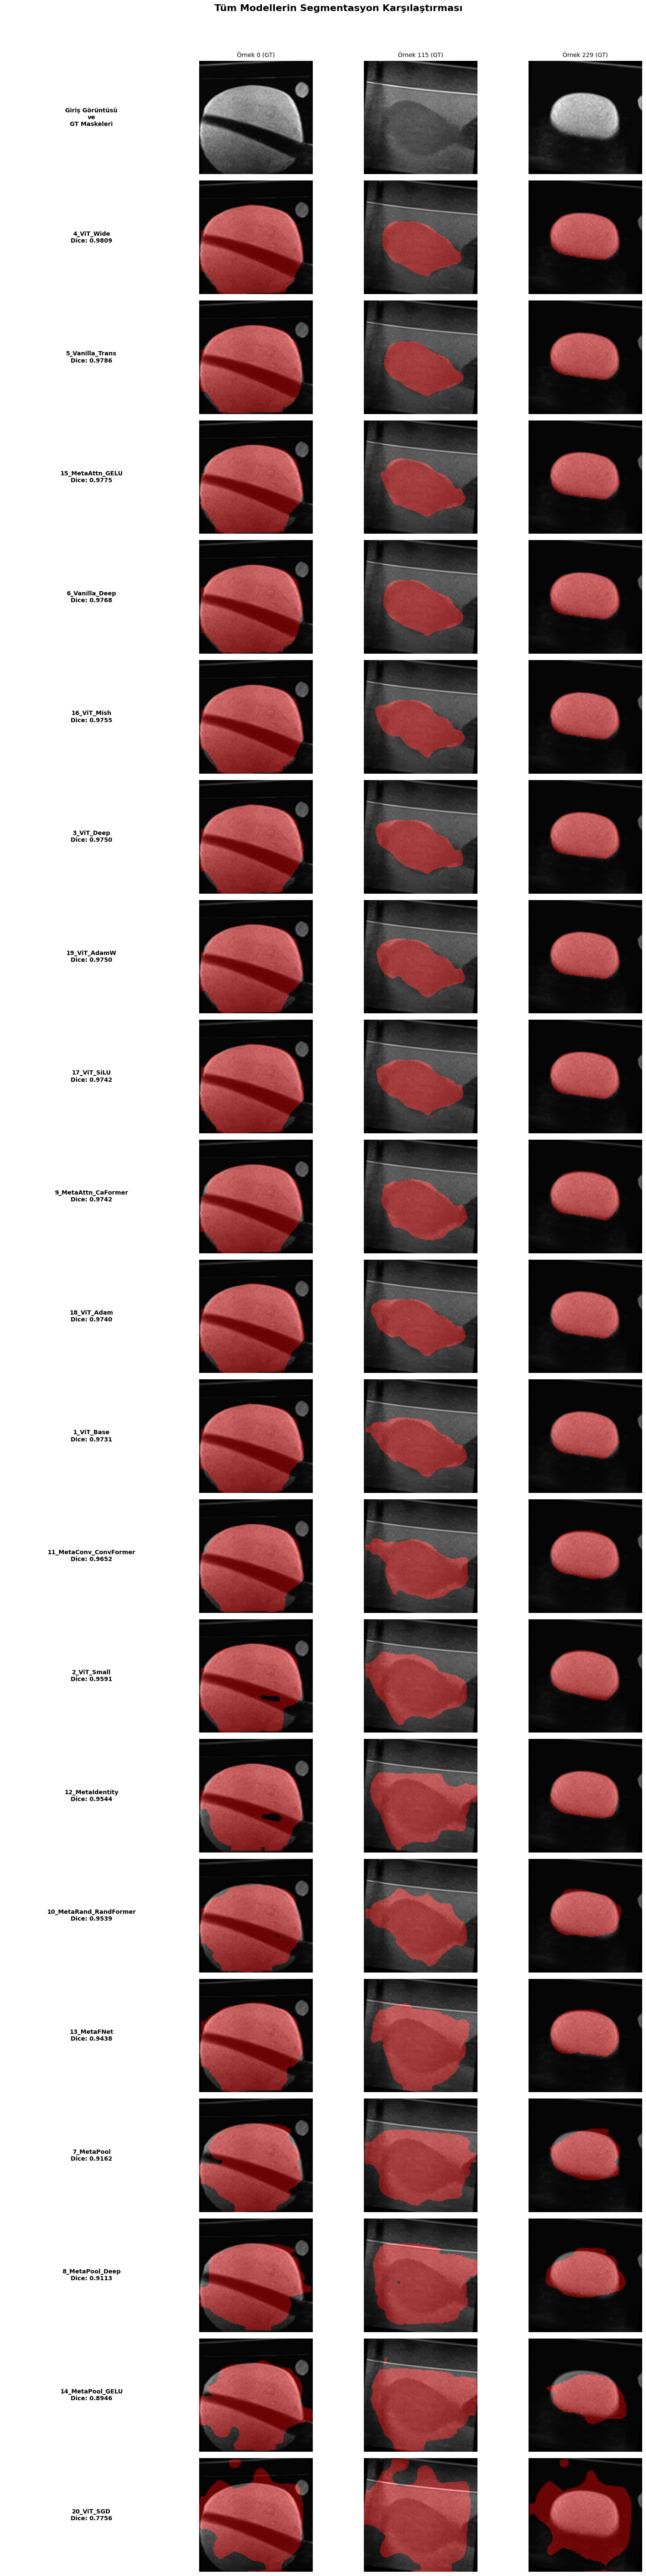

In [ ]:
# 1. Tüm sonuçları kullan (Filtreleme yapmıyoruz)
all_models_to_show = sorted_results  # En iyiden en kötüye sıralı tüm liste

num_samples = 3
sample_indices = [0, len(val_ds)//2, len(val_ds)-1]

# 2. Satır sayısını model sayısına göre dinamik olarak ayarlıyoruz
num_rows = len(all_models_to_show) + 1
fig, axes = plt.subplots(num_rows, num_samples + 1,
                         figsize=(4*(num_samples+1), 3*num_rows))

fig.suptitle('Tüm Modellerin Segmentasyon Karşılaştırması', fontsize=16, fontweight='bold', y=0.99)

# İlk satır: Ground Truth (Gerçek Maskeler)
axes[0, 0].text(0.5, 0.5, 'Giriş Görüntüsü\nve\nGT Maskeleri',
                ha='center', va='center', fontweight='bold')
axes[0, 0].axis('off')

for j, idx in enumerate(sample_indices):
    img, mask = val_ds[idx]
    # Görüntü ve maskeyi üst üste veya yan yana gösterebilirsin
    axes[0, j+1].imshow(img.squeeze(), cmap='gray')
    axes[0, j+1].set_title(f'Örnek {idx} (GT)', fontsize=10)
    axes[0, j+1].axis('off')

# Diğer satırlar: Her bir modelin tahmini
for i, res in enumerate(all_models_to_show):
    model = res['model']
    model.eval()

    # Model ismi ve skoru sol tarafa yazdır
    axes[i+1, 0].text(0.5, 0.5, f'{res["name"]}\nDice: {res["final_dice"]:.4f}',
                      ha='center', va='center', fontsize=10, fontweight='bold')
    axes[i+1, 0].axis('off')

    for j, idx in enumerate(sample_indices):
        img, mask = val_ds[idx]
        with torch.no_grad():
            pred = torch.sigmoid(model(img.unsqueeze(0).to(device))).squeeze().cpu()

        pred_bin = (pred > 0.5).float()

        # RGB overlay oluşturma
        img_np = img.squeeze().cpu().numpy()
        overlay = np.stack([img_np]*3, axis=-1)

        # Tahmini kırmızı kanala ekle (Rengi belirginleştirmek için 0.5 yapabilirsin)
        overlay[..., 0] += 0.4 * pred_bin.numpy()
        overlay = np.clip(overlay, 0, 1)

        axes[i+1, j+1].imshow(overlay)
        axes[i+1, j+1].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Başlık için boşluk bırak
plt.savefig('tum_modeller_karsilastirma.png', dpi=100, bbox_inches='tight')
plt.show()

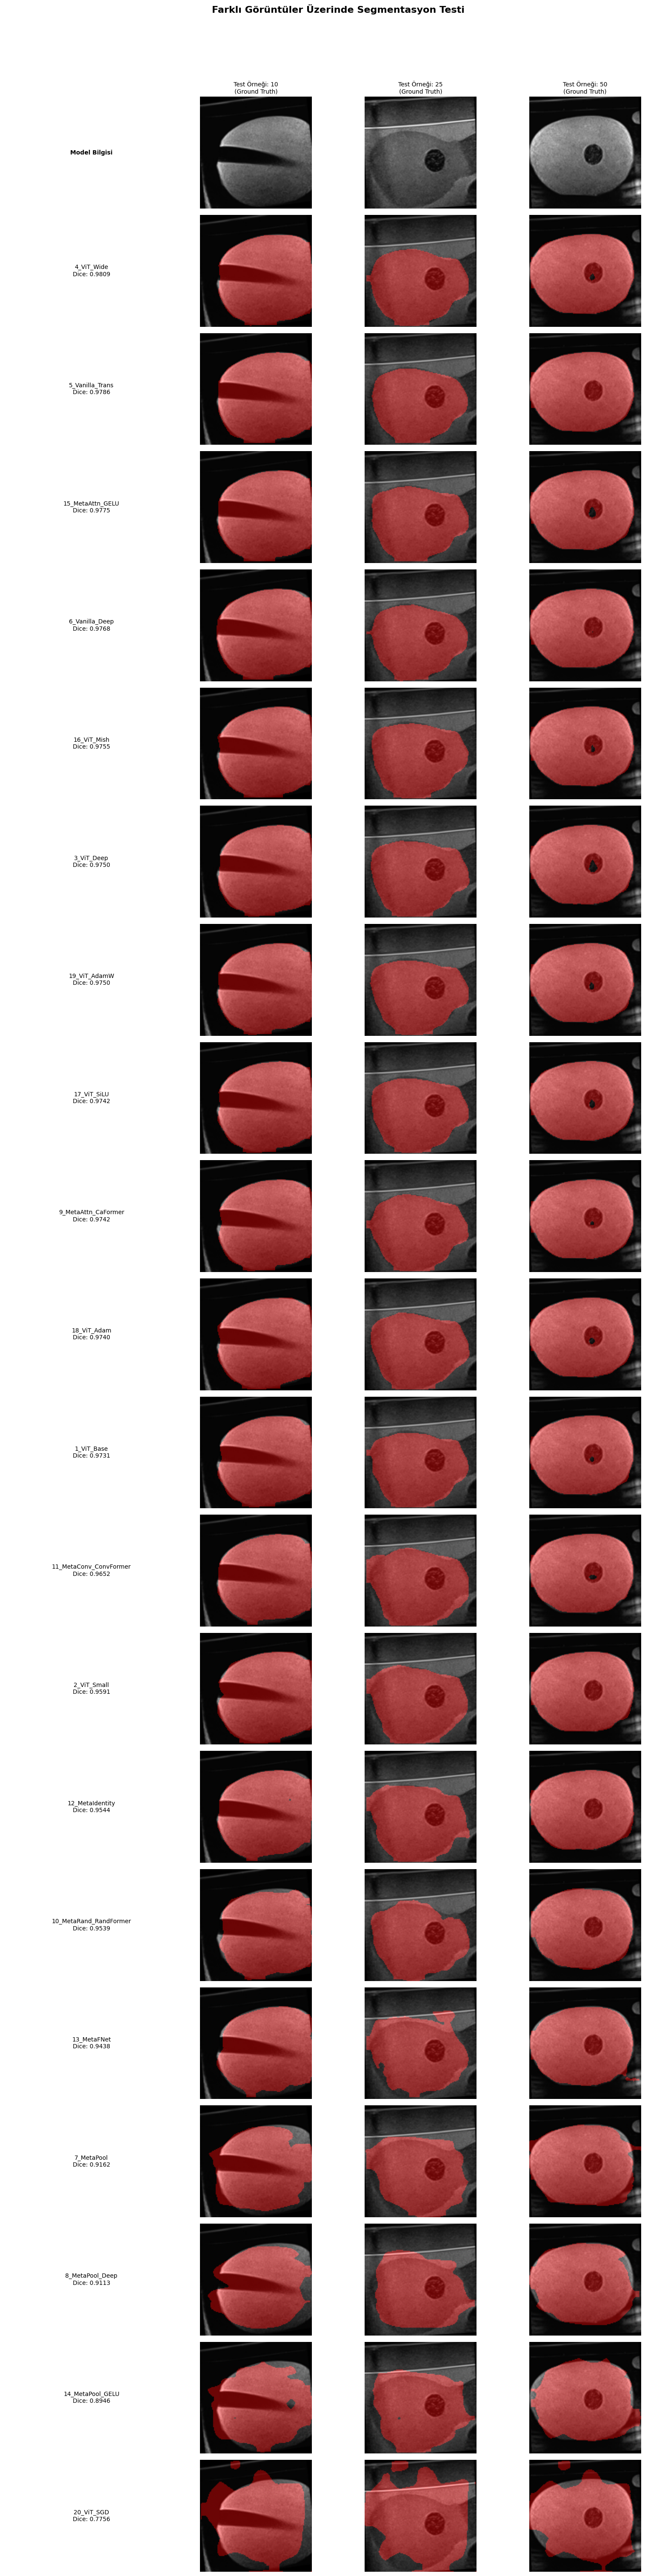

In [ ]:
new_sample_indices = [10, 25, 50]

num_samples = len(new_sample_indices)
num_rows = len(sorted_results) + 1

fig, axes = plt.subplots(num_rows, num_samples + 1,
                         figsize=(4*(num_samples+1), 3*num_rows))

fig.suptitle('Farklı Görüntüler Üzerinde Segmentasyon Testi', fontsize=16, fontweight='bold', y=0.99)

# Header Satırı
axes[0, 0].text(0.5, 0.5, 'Model Bilgisi', ha='center', va='center', fontweight='bold')
axes[0, 0].axis('off')

for j, idx in enumerate(new_sample_indices):
    img, mask = val_ds[idx]
    axes[0, j+1].imshow(img.squeeze(), cmap='gray')
    axes[0, j+1].set_title(f'Test Örneği: {idx}\n(Ground Truth)', fontsize=10)
    axes[0, j+1].axis('off')

# Modellerin Tahmin Döngüsü
for i, res in enumerate(sorted_results):
    model = res['model']
    model.eval()

    # Sol sütun: Model ismi
    axes[i+1, 0].text(0.5, 0.5, f'{res["name"]}\nDice: {res["final_dice"]:.4f}',
                      ha='center', va='center', fontsize=10)
    axes[i+1, 0].axis('off')

    for j, idx in enumerate(new_sample_indices):
        img, mask = val_ds[idx]

        with torch.no_grad():
            # Modeli cihazınıza gönderin (device: 'cuda' veya 'cpu')
            input_tensor = img.unsqueeze(0).to(device)
            output = model(input_tensor)
            pred = torch.sigmoid(output).squeeze().cpu()

        pred_bin = (pred > 0.5).float()

        # Görselleştirme: Orijinal görüntü üzerine kırmızı maske
        img_np = img.squeeze().cpu().numpy()
        overlay = np.stack([img_np]*3, axis=-1)
        overlay[..., 0] += 0.4 * pred_bin.numpy() # Kırmızı kanalına tahmin ekle
        overlay = np.clip(overlay, 0, 1)

        axes[i+1, j+1].imshow(overlay)
        axes[i+1, j+1].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()